# Air Quality in Indian Cities: Analysis Questions
**Course:** 23CSE351 – Foundations of Data Science | **Case Study – Part 2: Analysis Questions**

**Where we are:** Part 1 cleaned the data and explored it. Part 2 asks **15 analysis questions** about the data, answers each one with a statistic **and a chart**, and ends with a **decision**. Hypothesis tests (Part 3) and the ML model (Part 4) build on these decisions.

## How the questions were chosen
Part 1 showed that this data has special problems: AQI is **right-skewed**, coverage is **unbalanced** (cities start in different years), **Ahmedabad's CO is abnormal**, and many values were **filled**. So the questions are not "what is the average of group X?". Each question tests **what the data can and cannot tell us**, and each one leads to a decision that is used later.

Every question has the same five parts:
1. **Question and why it matters** – the decision it helps with.
2. **Concept from class** – the lecture idea used (L6 distributions, L7/L11 sampling, L9/L10 descriptive statistics, L14 causation).
3. **Chart – what it is and why we use it** – the reason this chart fits this question.
4. **Code and output.**
5. **Answer and decision** – plus what is carried to Part 3 (hypothesis test) or Part 4 (ML).

## Map of the 15 questions
| Group | # | Question (short) | Class concept | Chart |
|---|---|---|---|---|
| A. Can we trust the headline numbers? | 1 | Is the average AQI a fair "typical day"? | Mean, median, trimmed mean (L9) | Dot (dumbbell) plot |
| | 2 | Which cities are chronically bad and which are erratic? | SD, coefficient of variation (L10) | Labelled bubble scatter |
| | 3 | Which cities have rare extreme days? | Skewness, kurtosis (L10) | Scatter + histograms |
| B. What is AQI made of? | 4 | Which pollutant decides the AQI, and when? | Frequency / cross table (L7), AQI rule | Check scatter + 100% stacked bars |
| | 5 | Is the particle pollution fine smoke or coarse dust? | Ratio, five-number summary (L10) | Box plots |
| | 6 | Which pollutants repeat the same information? | Covariance vs correlation (L10), correlation ≠ causation (L14) | Correlation heatmap |
| C. When and why does it change? | 7 | How much worse is winter than monsoon inside each city? | Stratification (L14) | Dot (dumbbell) plot |
| | 8 | Is the yearly improvement real or caused by the changing city mix? | Confounding, sampling bias (L14, L7) | Line chart + bar chart |
| | 9 | Did the lockdown cause the 2020 drop? | Treatment vs control (L14) | Paired dot plot |
| | 10 | Does Diwali cause a jump beyond the seasonal climb? | Treatment window vs control cities (L14) | Event-window lines + dot plot |
| D. How reliable is our evidence? | 11 | Do bad days come independently or in streaks? | Bernoulli, Binomial, empirical distribution (L6, L11) | Bars vs Binomial curve |
| | 12 | Can we trust the ranking of cities? | Sampling variability, bootstrap (L11) | Interval (forest) plot |
| | 13 | How much does the sampling method change the result? | Sampling schemes, sampling distribution (L7, L11) | Overlaid density curves + line |
| | 14 | Does one city number hide local hot-spots? | Dispersion, range, data integration (L10, L8) | Bar chart + histogram |
| | 15 | How much of today's AQI is known from yesterday? | Covariance / correlation (L10) | Lag scatter + bar chart |

## Rules used in the whole notebook
- **Ahmedabad** is left out of every comparison between cities or years (CO problem from Part 1). It is shown separately where it is the point of the question (Q1-Q4).
- Because AQI is skewed (Q1), we use the **median** unless a question needs the mean.
- Where Part 1 showed that **filling** would mislead (particle ratio, correlations), we use the **original, un-filled readings**.
- The data is observational, so we describe **associations**; claims about cause are marked as such (L14).

## 0. Setup
Load the three clean files from Part 1 (run Part 1 first so that `city_day_clean.csv` and `station_day_clean.csv` exist) and the original `city_day.csv` for the questions that need un-filled values.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(42)          # fixed seed: simulations give the same result every run

df  = pd.read_csv('city_day_clean.csv',    parse_dates=['Date'])   # cleaned in Part 1 (main data)
sd  = pd.read_csv('station_day_clean.csv', parse_dates=['Date'])   # cleaned station data
raw = pd.read_csv('city_day.csv',          parse_dates=['Date'])   # original file with its real gaps (no filling)

SEASONS = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
month_to_season = {12:'Winter', 1:'Winter', 2:'Winter', 3:'Summer', 4:'Summer', 5:'Summer',
                   6:'Monsoon', 7:'Monsoon', 8:'Monsoon', 9:'Monsoon', 10:'Post-Monsoon', 11:'Post-Monsoon'}
city_region = df.drop_duplicates('City').set_index('City')['Region']

raw['Season'] = raw['Date'].dt.month.map(month_to_season)     # same season rule as Part 1
raw['Region'] = raw['City'].map(city_region)

ex = df[df['City'] != 'Ahmedabad']       # "ex" = without Ahmedabad (its CO readings are abnormal, see Part 1)
print('Clean city data:', df.shape, '| cities:', df['City'].nunique(), '| days with AQI:', len(df))

Clean city data: (24850, 36) | cities: 26 | days with AQI: 24850


# GROUP A – Can we trust the headline numbers?
Before using any number, we check how reliable it is. Three questions use **central tendency, spread and shape** (L9, L10).

## Q1. Is the average AQI a fair picture of a "typical day" in each city?
**Why it matters:** Reports usually give one average AQI per city. If a few extreme days pull the average up, the city looks worse than a normal day really is. We need to know which number to quote.

**Concept from class:** Mean, median and trimmed mean (L9); skewness (L10). The mean is pulled towards the tail, so for skewed data the median is a better centre.

**Chart – what it is and why we use it:** A **dot (dumbbell) plot**: one row per city with three dots (median, 10% trimmed mean, mean) joined by a grey bar. The question is about the *distance* between three summaries for 26 cities, so the length of the grey bar *is* the answer. A bar chart would hide the gap, and 26 histograms would be too many to compare.

In [2]:
g = df.groupby('City')['AQI']
q1 = pd.DataFrame({'Days': g.size(),
                   'Median': g.median(),
                   'Trimmed mean (10%)': g.apply(lambda x: stats.trim_mean(x, 0.1)),   # drop lowest and highest 10%, then average
                   'Mean': g.mean()})
q1['Mean above median (%)'] = (q1['Mean'] / q1['Median'] - 1) * 100

print('Skewness of daily AQI  -> all cities: %.2f | without Ahmedabad: %.2f' % (stats.skew(df['AQI']), stats.skew(ex['AQI'])))
print('Pooled AQI -> mean %.0f | 10%% trimmed mean %.0f | median %.0f' % (df['AQI'].mean(), stats.trim_mean(df['AQI'], .1), df['AQI'].median()))
display(q1.sort_values('Mean above median (%)', ascending=False).round(1).head(6))
display(q1.sort_values('Mean above median (%)').round(1).head(4))

Skewness of daily AQI  -> all cities: 3.40 | without Ahmedabad: 1.51
Pooled AQI -> mean 166 | 10% trimmed mean 143 | median 118


,Days,Median,Trimmed mean (10%),Mean,Mean above median (%)
City,,,,,
Aizawl,111,23.0,31.6,34.8,51.2
Kolkata,754,94.0,124.9,140.6,49.5
Guwahati,495,98.0,126.1,140.1,43.0
Talcher,698,128.5,160.1,172.9,34.5
Brajrajnagar,713,122.0,142.1,150.3,23.2
Amaravati,841,78.0,86.2,95.3,22.2


,Days,Median,Trimmed mean (10%),Mean,Mean above median (%)
City,,,,,
Coimbatore,344,75.0,74.0,73.0,-2.6
Ernakulam,153,94.0,91.8,92.4,-1.7
Delhi,1999,257.0,254.9,259.5,1.0
Hyderabad,1880,104.0,104.1,109.2,5.0


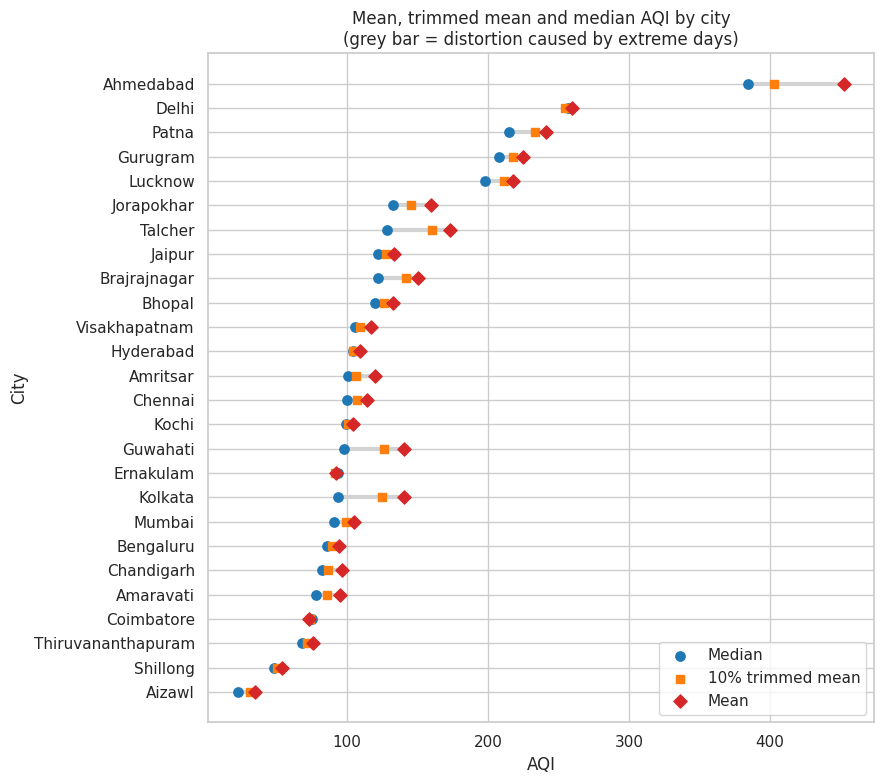

In [3]:
q1s = q1.sort_values('Median')
y = np.arange(len(q1s))
fig, ax = plt.subplots(figsize=(9, 8))
ax.hlines(y, q1s['Median'], q1s['Mean'], color='lightgrey', lw=3, zorder=1)        # grey bar = how far the mean is from the median
ax.scatter(q1s['Median'],             y, color='tab:blue',   s=45, label='Median', zorder=3)
ax.scatter(q1s['Trimmed mean (10%)'], y, color='tab:orange', s=40, marker='s', label='10% trimmed mean', zorder=3)
ax.scatter(q1s['Mean'],               y, color='tab:red',    s=45, marker='D', label='Mean', zorder=3)
ax.set_yticks(y); ax.set_yticklabels(q1s.index)
ax.set_xlabel('AQI'); ax.set_ylabel('City')
ax.set_title('Mean, trimmed mean and median AQI by city\n(grey bar = distortion caused by extreme days)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

**What the output shows:**
- Pooled over all days: **mean 166, trimmed mean 143, median 118**, skewness 3.40 (1.51 without Ahmedabad). The mean is far above the median, which is the sign of a right tail.
- The mean overstates a typical day most in **Aizawl (+51%), Kolkata (+50%), Guwahati (+43%) and Talcher (+35%)**.
- **Delhi is different:** mean 259.5 and median 257 (+1%). Its air is high on almost every day, so there are no rare spikes pulling the mean up. Coimbatore and Ernakulam also have mean ≈ median.

**Answer and decision:** No, the mean is *not* a fair "typical day" for most cities because a few very bad days inflate it. **We use the median (and the share of bad days, Q12) to compare cities.** The mean is only safe for steady cities like Delhi. Aizawl has only 111 days, so its numbers are less certain.

**Carried to Part 3:** one-sample test – is Delhi's typical AQI above the 200 "Poor" limit?

## Q2. Which cities are *consistently* polluted and which are *erratic*?
**Why it matters:** Two cities can have the same average AQI but very different problems: one is bad every day (needs long-term control), the other has sudden bad episodes (needs warnings and emergency action).

**Concept from class:** Standard deviation and the **coefficient of variation (CV = SD / mean)** (L10). CV has no unit, so cities with very different levels can be compared fairly; SD alone would always be larger for polluted cities.

**Chart – what it is and why we use it:** A **labelled bubble scatter** with mean AQI on the x-axis and CV on the y-axis. Two numbers per city are needed at the same time (level and variability), and the dashed median lines split the chart into four types of city. Bubble size shows how many days each city has, so we know how much to trust each dot.

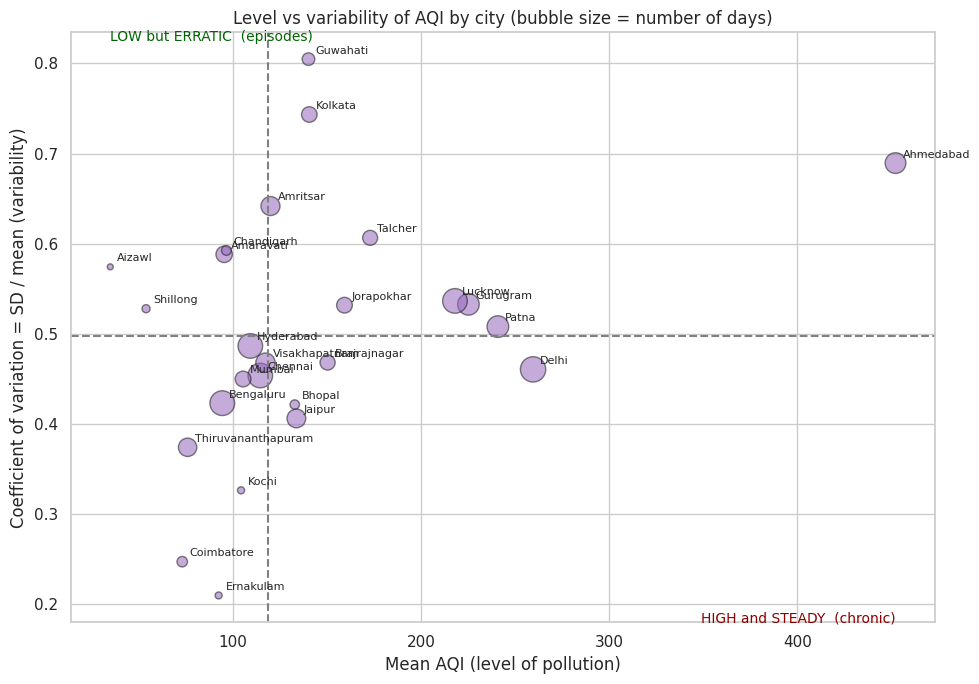

,Mean,SD,Days,CV
City,,,,
Ernakulam,92.36,19.39,153,0.21
Coimbatore,73.02,18.06,344,0.25
Kochi,104.28,34.05,158,0.33
Ahmedabad,452.12,311.73,1334,0.69
Kolkata,140.57,104.49,754,0.74
Guwahati,140.11,112.76,495,0.80


In [4]:
q2 = df.groupby('City')['AQI'].agg(Mean='mean', SD='std', Days='count')
q2['CV'] = q2['SD'] / q2['Mean']                       # coefficient of variation = SD / mean (no unit)
x_cut, y_cut = q2['Mean'].median(), q2['CV'].median()

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(q2['Mean'], q2['CV'], s=q2['Days'] / 6, alpha=.55, color='tab:purple', edgecolor='k')
for c, r in q2.iterrows():
    ax.annotate(c, (r['Mean'], r['CV']), fontsize=8, xytext=(5, 4), textcoords='offset points')
ax.axvline(x_cut, color='grey', ls='--'); ax.axhline(y_cut, color='grey', ls='--')
ax.text(q2['Mean'].max(), q2['CV'].min() - .03, 'HIGH and STEADY  (chronic)', ha='right', color='darkred', fontsize=10)
ax.text(q2['Mean'].min(), q2['CV'].max() + .02, 'LOW but ERRATIC  (episodes)', ha='left', color='darkgreen', fontsize=10)
ax.set_xlabel('Mean AQI (level of pollution)'); ax.set_ylabel('Coefficient of variation = SD / mean (variability)')
ax.set_title('Level vs variability of AQI by city (bubble size = number of days)')
plt.tight_layout(); plt.show()
display(q2.sort_values('CV').round(2).iloc[[0, 1, 2, -3, -2, -1]])

**What the output shows:**
- **Most steady:** Ernakulam (CV 0.21), Coimbatore (0.25) and Kochi (0.33), but all three have *low* AQI. Their air is both clean and predictable.
- **Most erratic:** Guwahati (CV 0.80), Kolkata (0.74) and Ahmedabad (0.69). Guwahati and Kolkata have a moderate average (about 140), so their average hides some very bad days.
- **Delhi:** mean 259 with CV 0.46, the highest level among the cities with low variability. Lucknow, Gurugram and Patna also sit on the right side of the chart (mean 218-241, CV 0.51-0.54).

**Answer and decision:** There are **two different problems**. *Chronic* cities (Delhi, Patna, Gurugram, Lucknow) have bad air most winter days; *episodic* cities (Guwahati, Kolkata, Amritsar) have a lower average but sudden bad stretches. In the report and dashboard, cities should be described by **level and CV together**, not by one average.

## Q3. Do some cities suffer sudden spikes instead of steady pollution?
**Why it matters:** Q2 shows how *much* AQI varies. This question asks *how* it varies: many moderate swings, or mostly normal days with a few extreme ones? Extreme days are the dangerous ones and they also create large errors in ML models.

**Concept from class:** Skewness and **kurtosis** (L10). Excess kurtosis above 0 means heavier tails than the normal curve, i.e. extreme values happen more often than a bell curve predicts. Negative means lighter tails.

**Chart – what it is and why we use it:** A **scatter of skewness vs excess kurtosis** (one point per city) to find the unusual cities, and next to it the **histograms** of one steady city (Delhi) and one spike city (Hyderabad) so the numbers can be *seen* as shapes. The scatter finds the cities, the histograms explain what the numbers mean.

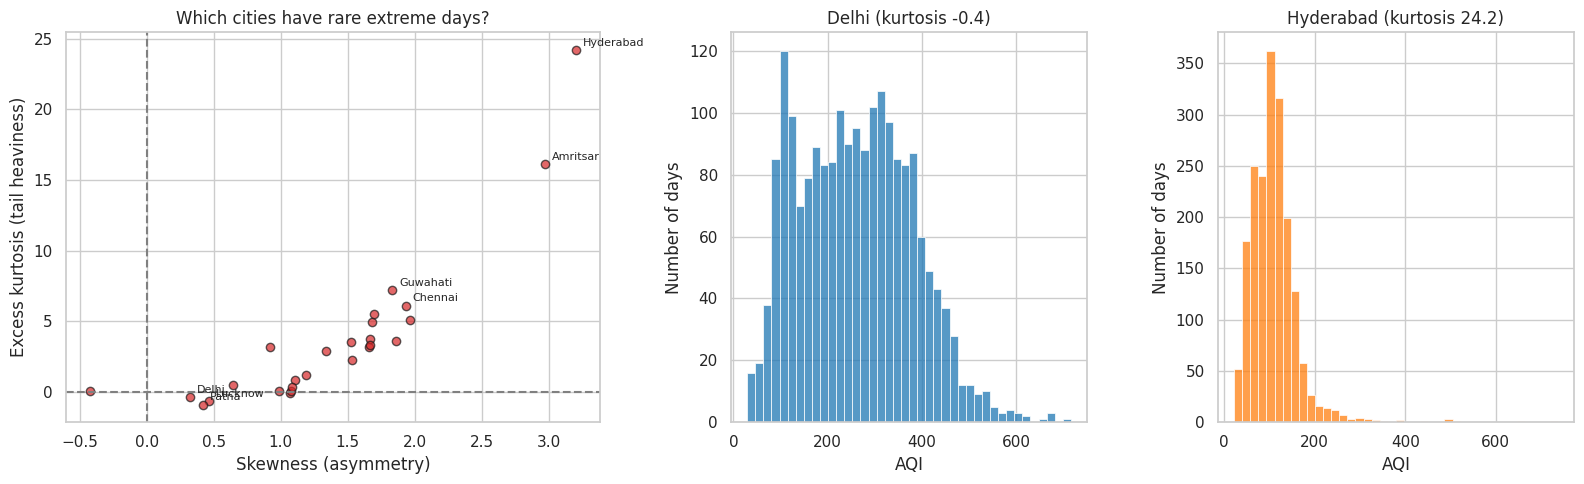

,Skewness,Excess_kurtosis
City,,
Hyderabad,3.20,24.21
Amritsar,2.97,16.12
Guwahati,1.83,7.18
Chennai,1.93,6.10
Kochi,1.70,5.47


Hyderabad: median AQI 104, max AQI 737, days above 300: 17 of 1880


In [5]:
q3 = df.groupby('City')['AQI'].agg(Skewness=stats.skew, Excess_kurtosis=stats.kurtosis)   # excess kurtosis: 0 = normal curve

fig = plt.figure(figsize=(16, 5))
gs = fig.add_gridspec(1, 3, width_ratios=[1.5, 1, 1])
ax = fig.add_subplot(gs[0])
ax.scatter(q3['Skewness'], q3['Excess_kurtosis'], color='tab:red', alpha=.7, edgecolor='k')
for c, r in q3.iterrows():
    if c in ['Hyderabad', 'Amritsar', 'Guwahati', 'Chennai', 'Delhi', 'Lucknow', 'Patna']:
        ax.annotate(c, (r['Skewness'], r['Excess_kurtosis']), fontsize=8, xytext=(5, 3), textcoords='offset points')
ax.axhline(0, color='grey', ls='--'); ax.axvline(0, color='grey', ls='--')
ax.set_xlabel('Skewness (asymmetry)'); ax.set_ylabel('Excess kurtosis (tail heaviness)')
ax.set_title('Which cities have rare extreme days?')

for k, (city, col) in enumerate([('Delhi', 'tab:blue'), ('Hyderabad', 'tab:orange')], start=1):
    a = fig.add_subplot(gs[k])
    sns.histplot(df.loc[df['City'] == city, 'AQI'], bins=40, color=col, ax=a)
    a.set_xlabel('AQI'); a.set_ylabel('Number of days'); a.set_title(f'{city} (kurtosis {q3.loc[city, "Excess_kurtosis"]:.1f})')
plt.tight_layout(); plt.show()
display(q3.sort_values('Excess_kurtosis', ascending=False).round(2).head(5))
print('Hyderabad: median AQI %.0f, max AQI %.0f, days above 300: %d of %d' % (
      df.loc[df.City=='Hyderabad','AQI'].median(), df.loc[df.City=='Hyderabad','AQI'].max(),
      (df.loc[df.City=='Hyderabad','AQI'] > 300).sum(), (df.City=='Hyderabad').sum()))

**What the output shows:**
- **Heavy tails:** Hyderabad (excess kurtosis 24.2), Amritsar (16.1), Guwahati (7.2), Chennai (6.1) and Kochi (5.5).
- **Light tails:** Delhi (-0.4), Lucknow (-0.6) and Patna (-0.9). Their distributions are wide and flat, with no rare extreme days.
- Hyderabad's median is 104 and only **17 of 1,880 days are above 300**, but the maximum is 737. The histogram shows a tight group of ordinary days and a very thin long tail.

**Answer and decision:** Yes. **Hyderabad, Amritsar, Guwahati and Chennai have mostly ordinary days with a few extreme ones**; the northern cities do not have rare spikes because their whole distribution sits high. So the average is not the right summary for spike cities (it agrees with Q1), and in Part 4 these extreme days will give the largest prediction errors. We will report **MAE as well as RMSE** and keep the log version of AQI.

# GROUP B – What is AQI made of?
AQI is not an average of pollutants. Q4 shows how it is built, and Q5-Q6 use that to understand the pollutants.

## Q4. Which pollutant actually decides the AQI, and does it change with the season?
**Why it matters:** Knowing the "worst pollutant of the day" tells us what to control and which features matter for ML. Part 1 suspected that Ahmedabad's AQI is driven by CO; this question tests that with evidence.

**Concept from class:** Frequency and cross tables (L7: "data tables and charts") applied to a *derived column*. The CPCB rule is: each pollutant gets a **sub-index** (0-500) from its concentration and **AQI = the highest sub-index of the day**. We rebuild the sub-indices from the pollutant columns, and the pollutant with the highest one is the **dominant pollutant**.

**Chart – what it is and why we use it:** (1) A **validation scatter** of rebuilt AQI against reported AQI. If our rebuild does not match the real AQI, the "dominant pollutant" claim would be meaningless, so this check must come first. (2) A **100% stacked bar** per season: it compares the *composition* (share) of dominant pollutants across groups that have different numbers of days. Ahmedabad gets its own bar.

In [6]:
# CPCB rule: each pollutant gets a SUB-INDEX (0-500) from its concentration; AQI = the largest sub-index of the day.
A  = [0, 50, 100, 200, 300, 400, 500]                          # AQI points
BP = {'PM2.5': [0, 30, 60, 90, 120, 250, 380],                  # matching concentration breakpoints (ug/m3; CO in mg/m3)
      'PM10' : [0, 50, 100, 250, 350, 430, 510],
      'NO2'  : [0, 40, 80, 180, 280, 400, 520],
      'SO2'  : [0, 40, 80, 380, 800, 1600, 2100],
      'CO'   : [0, 1, 2, 10, 17, 34, 50],
      'O3'   : [0, 50, 100, 168, 208, 748, 900],
      'NH3'  : [0, 200, 400, 800, 1200, 1800, 2400]}

def sub_index(x, bp):
    s = np.interp(x.fillna(0), bp, A)                                         # straight line inside each band
    hi = (x > bp[-1]).values
    s[hi] = 500 + (x[hi] - bp[-1]) * 100 / (bp[-1] - bp[-2])                  # above the table: keep rising
    return pd.Series(s, index=x.index).where(x.notna())                       # a missing pollutant stays missing

sub = pd.DataFrame({p: sub_index(raw[p], BP[p]) for p in BP})
valid = (sub.notna().sum(axis=1) >= 3) & sub[['PM2.5', 'PM10']].notna().any(axis=1)    # CPCB: >=3 pollutants, one of them PM
raw['AQI_calc'] = sub.max(axis=1).where(valid)
raw['Dominant'] = sub.fillna(-1).idxmax(axis=1).where(valid)                  # pollutant with the largest sub-index

cmp_ = raw.dropna(subset=['AQI', 'AQI_calc'])
diff = (cmp_['AQI'] - cmp_['AQI_calc']).abs()
print('Days compared: %d | correlation reported vs rebuilt AQI: %.2f | within 20 AQI points: %.0f%%' % (
      len(cmp_), np.corrcoef(cmp_['AQI'], cmp_['AQI_calc'])[0, 1], (diff <= 20).mean() * 100))
print('\nDominant pollutant, share of days (%):')
print((cmp_['Dominant'].value_counts(normalize=True) * 100).round(1).to_string())

Days compared: 24785 | correlation reported vs rebuilt AQI: 0.89 | within 20 AQI points: 61%

Dominant pollutant, share of days (%):
Dominant
PM2.5    41.3
PM10     38.4
CO       15.4
O3        3.2
NO2       1.4
SO2       0.3
NH3       0.1


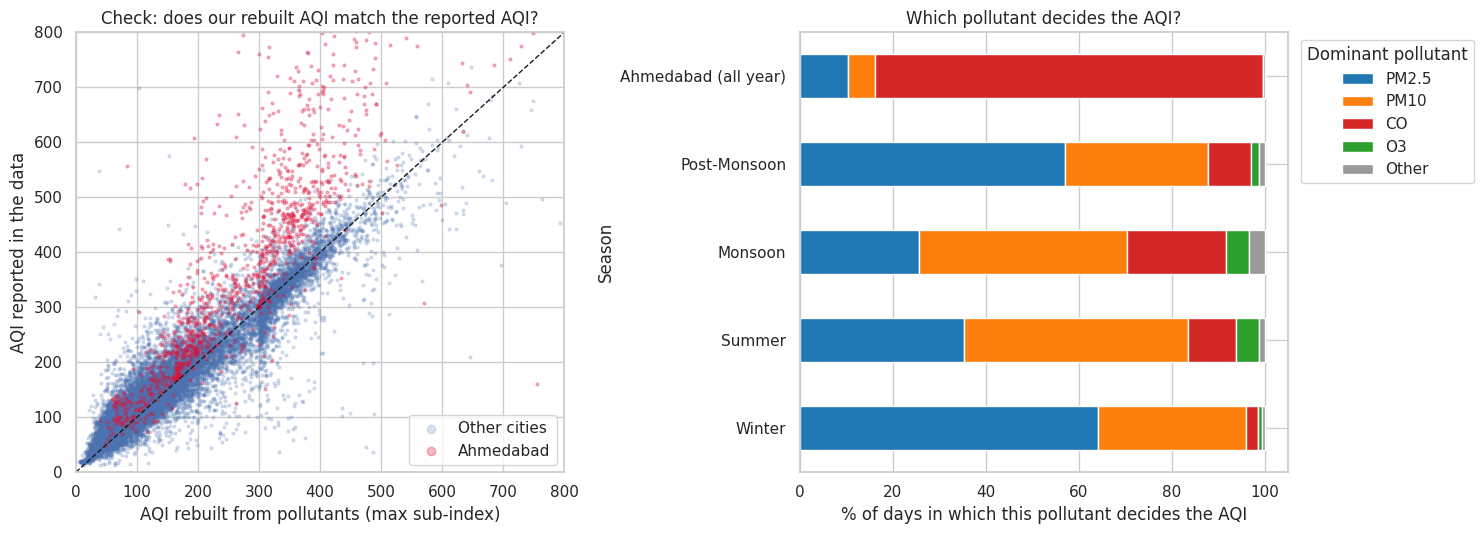

Dom,PM2.5,PM10,CO,O3,Other
Season,,,,,
Winter,64.0,32.0,3.0,1.0,1.0
Summer,35.0,48.0,10.0,5.0,1.0
Monsoon,26.0,45.0,21.0,5.0,3.0
Post-Monsoon,57.0,31.0,9.0,2.0,1.0
Ahmedabad (all year),10.0,6.0,83.0,0.0,0.0


In [7]:
show = ['PM2.5', 'PM10', 'CO', 'O3', 'Other']
cmp_['Dom'] = cmp_['Dominant'].where(cmp_['Dominant'].isin(show[:4]), 'Other')
no_ahd = cmp_[cmp_['City'] != 'Ahmedabad']
tab = pd.crosstab(no_ahd['Season'], no_ahd['Dom'], normalize='index')[show] * 100
tab.loc['Ahmedabad (all year)'] = cmp_.loc[cmp_['City'] == 'Ahmedabad', 'Dom'].value_counts(normalize=True).reindex(show).fillna(0) * 100
tab = tab.loc[SEASONS + ['Ahmedabad (all year)']]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
is_a = cmp_['City'] == 'Ahmedabad'
axes[0].scatter(cmp_.loc[~is_a, 'AQI_calc'], cmp_.loc[~is_a, 'AQI'], s=4, alpha=.2, label='Other cities')
axes[0].scatter(cmp_.loc[is_a, 'AQI_calc'],  cmp_.loc[is_a, 'AQI'],  s=4, alpha=.3, color='crimson', label='Ahmedabad')
axes[0].plot([0, 800], [0, 800], 'k--', lw=1); axes[0].set_xlim(0, 800); axes[0].set_ylim(0, 800)
axes[0].set_xlabel('AQI rebuilt from pollutants (max sub-index)'); axes[0].set_ylabel('AQI reported in the data')
axes[0].set_title('Check: does our rebuilt AQI match the reported AQI?'); axes[0].legend(markerscale=3)

tab.plot(kind='barh', stacked=True, ax=axes[1], color=['#1f77b4', '#ff7f0e', '#d62728', '#2ca02c', '#999999'])
axes[1].set_xlabel('% of days in which this pollutant decides the AQI'); axes[1].set_ylabel('Season')
axes[1].set_title('Which pollutant decides the AQI?'); axes[1].legend(title='Dominant pollutant', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()
display(tab.round(0))

**What the output shows:**
- **Validation:** rebuilt and reported AQI have correlation **0.89**, and 61% of days are within 20 AQI points. This is a good match, but not exact: CPCB uses 8-hour values for CO and O3, while we only have daily averages. Ahmedabad's points (red) sit *above* the line, so its reported AQI is higher than daily averages explain.
- **Overall:** PM2.5 decides 41% of days, PM10 38%, CO 15%, O3 3%.
- **By season (without Ahmedabad):** PM2.5 decides **64% of winter** and 57% of post-monsoon days; PM10 is the main pollutant in summer (48%) and monsoon (45%). In the monsoon, rain removes particles, so CO more often (21%) becomes the highest sub-index.
- **Ahmedabad:** CO decides **83% of days**.

**Answer and decision:**
1. AQI is the **worst single pollutant**, not a mix: PM2.5 in winter and post-monsoon, PM10 in summer and monsoon.
2. Part 1's suspicion is confirmed: **Ahmedabad's high AQI comes from CO**.
3. **Important for Part 4:** AQI is calculated from these same pollutants (our rebuild already reaches r = 0.89). A model that predicts AQI from same-day pollutants is almost solving the CPCB formula, not forecasting. We will frame the ML task honestly (next-day prediction, see Q15) and say so in the justification.

**Carried to Part 3:** chi-square test of independence between season and dominant pollutant (L13).

## Q5. Is the particle pollution mostly fine smoke or coarse dust?
**Why it matters:** PM2.5 (fine) goes deep into the lungs and comes mostly from burning (vehicles, fires), while the coarse part of PM10 is mostly dust. The **PM2.5 / PM10 ratio** tells which kind dominates, and whether bad days are made of a *different kind* of pollution, not only *more* of it.

**Concept from class:** A ratio as a new variable, compared across groups using the **five-number summary** (median, quartiles, whiskers) from L10.

**Chart – what it is and why we use it:** **Box plots**, because they show the median and spread of the ratio for each group in one view and make groups easy to compare. One panel groups by season, the other by AQI level of the day. Only **real readings** are used (the 256 rows where PM2.5 > PM10 are impossible, and filled PM10 values would distort a ratio).

Days used: 17376 | median ratio: 0.47


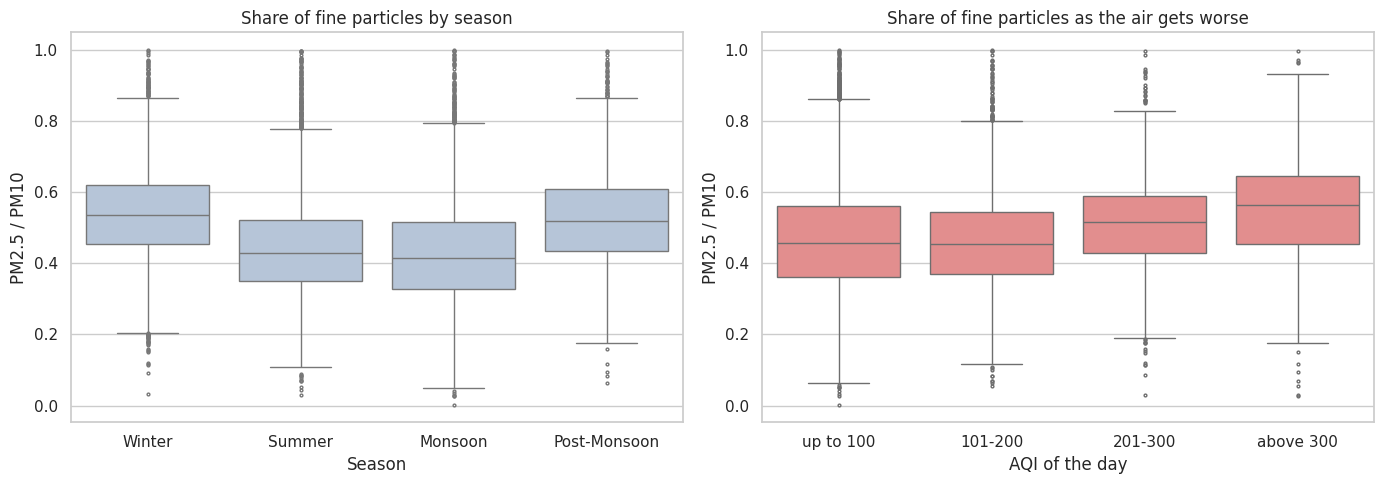

,median,count
City,,
Mumbai,0.33,762
Talcher,0.35,694
Bhopal,0.39,280
Shillong,0.68,223
Aizawl,0.69,110
Coimbatore,0.78,371


{'Winter': 0.54, 'Summer': 0.43, 'Monsoon': 0.41, 'Post-Monsoon': 0.52}
{'up to 100': 0.46, '101-200': 0.45, '201-300': 0.52, 'above 300': 0.57}


In [8]:
r = raw.dropna(subset=['PM2.5', 'PM10'])
r = r[(r['PM2.5'] <= r['PM10']) & (r['PM10'] > 0)].copy()      # real readings only; the 256 impossible rows (PM2.5 > PM10) are left out
r['Ratio'] = r['PM2.5'] / r['PM10']
r['AQI band'] = pd.cut(r['AQI'], [0, 100, 200, 300, 5000], labels=['up to 100', '101-200', '201-300', 'above 300'])
print('Days used:', len(r), '| median ratio: %.2f' % r['Ratio'].median())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=r, x='Season', y='Ratio', order=SEASONS, color='lightsteelblue', ax=axes[0], flierprops=dict(markersize=2))
axes[0].set_xlabel('Season'); axes[0].set_ylabel('PM2.5 / PM10'); axes[0].set_title('Share of fine particles by season')
sns.boxplot(data=r.dropna(subset=['AQI band']), x='AQI band', y='Ratio', color='lightcoral', ax=axes[1], flierprops=dict(markersize=2))
axes[1].set_xlabel('AQI of the day'); axes[1].set_ylabel('PM2.5 / PM10'); axes[1].set_title('Share of fine particles as the air gets worse')
plt.tight_layout(); plt.show()

by_city = r.groupby('City')['Ratio'].agg(['median', 'count']).sort_values('median')
display(pd.concat([by_city.head(3), by_city.tail(3)]).round(2))
print(r.groupby('Season')['Ratio'].median().round(2).reindex(SEASONS).to_dict())
print(r.groupby('AQI band')['Ratio'].median().round(2).to_dict())

**What the output shows:**
- Overall median ratio **0.47** (17,376 days): about half of PM10 is fine particles.
- **Season:** winter 0.54 and post-monsoon 0.52, against summer 0.43 and monsoon 0.41.
- **AQI level:** 0.46 (up to 100), 0.45 (101-200), 0.52 (201-300), **0.57 (above 300)**.
- **City:** lowest Mumbai (0.33), Talcher (0.35), Bhopal (0.39); highest Coimbatore (0.78), Aizawl (0.69), Shillong (0.68). The highest ones are small, clean cities, so they are less reliable.

**Answer and decision:** Yes, the share of fine particles **rises in winter and on the worst days**. This is typical of smoke from burning rather than only dust (it is an interpretation, not proved by this data). So PM2.5 is the key pollutant for health, and the **ratio can be an extra feature** in Part 4.

**Carried to Part 3:** two-sample test of the ratio, winter vs monsoon (L13).

## Q6. Which pollutants repeat the same information?
**Why it matters:** If two pollutants move together, using both in a regression adds no new information and makes the coefficients unstable (multicollinearity). We must choose features *before* building the ML model.

**Concept from class:** **Covariance** shows direction but its size depends on the units (L10), so we convert it to **correlation**, which is always between -1 and 1. We also apply L14: a high correlation is not a cause.

**Chart – what it is and why we use it:** A **correlation heatmap**: with 12 variables there are 66 pairs, and colour lets us find the strong ones at a glance. It uses the **log of real, un-filled readings** without Ahmedabad: log reduces skew (Part 1), and Part 1 showed that filled values weaken correlations.

COVARIANCE (original units) - the size depends on the units, so it cannot be compared:


,PM2.5,NO2,O3
PM2.5,4335.0,574.0,232.0
NO2,574.0,450.0,133.0
O3,232.0,133.0,467.0


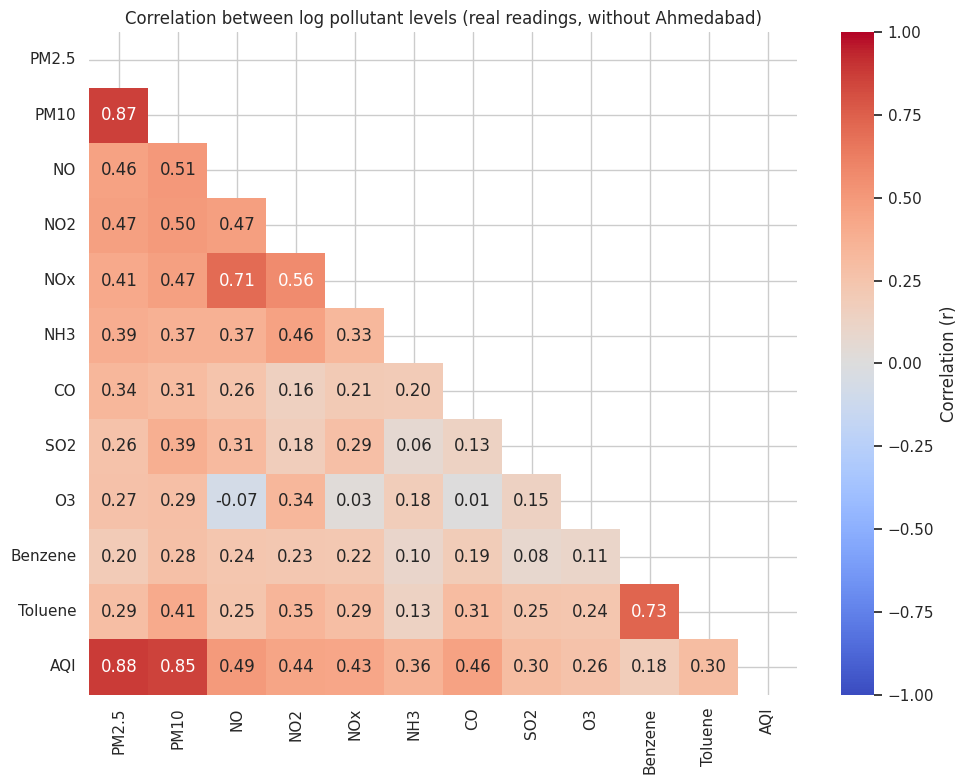

Pollutant pairs with |r| >= 0.6 (duplicate information):


,,r
PM10,PM2.5,0.87
Toluene,Benzene,0.73
NOx,NO,0.71


Correlation with AQI:
PM2.5      0.88
PM10       0.85
NO         0.49
CO         0.46
NO2        0.44
NOx        0.43
NH3        0.36
SO2        0.30
Toluene    0.30
O3         0.26
Benzene    0.18


In [9]:
P = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
real = raw[raw['City'] != 'Ahmedabad']                      # real readings only (no filled values), without Ahmedabad

print('COVARIANCE (original units) - the size depends on the units, so it cannot be compared:')
display(real[['PM2.5', 'NO2', 'O3']].cov().round(0))

corr = np.log1p(real[P + ['AQI']]).corr()                   # log removes skew; pandas uses all days where both values exist
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, cbar_kws={'label': 'Correlation (r)'})
plt.title('Correlation between log pollutant levels (real readings, without Ahmedabad)')
plt.tight_layout(); plt.show()

pairs = corr.where(~mask).stack()
pairs = pairs[pairs.index.get_level_values(0) != 'AQI']
pairs = pairs[pairs.index.get_level_values(1) != 'AQI']
print('Pollutant pairs with |r| >= 0.6 (duplicate information):')
display(pairs[pairs.abs() >= 0.6].sort_values(ascending=False).round(2).to_frame('r'))
print('Correlation with AQI:'); print(corr['AQI'].drop('AQI').sort_values(ascending=False).round(2).to_string())

**What the output shows:**
- **Covariance cannot be compared:** the PM2.5-NO2 covariance (574) looks 2.5 times the PM2.5-O3 covariance (232), but PM2.5 simply has much larger numbers (its variance is 4,335 against 450-467).
- **Pairs with |r| of at least 0.6:** **PM2.5-PM10 (0.87)**, **Toluene-Benzene (0.73)** and **NO-NOx (0.71)**.
- **Correlation with AQI:** PM2.5 **0.88** and PM10 **0.85** are far ahead; NO 0.49, CO 0.46, NO2 0.44 and NOx 0.43 are moderate; Benzene 0.18 and O3 0.26 are weak.

**Answer and decision:** PM2.5 and PM10 carry largely the same information, NOx repeats NO (it is made of NO and NO2), and Toluene and Benzene overlap. **Feature plan for Part 4:** keep PM2.5, and either PM10 or the PM2.5/PM10 ratio (Q5), plus NO2, CO, SO2 and O3; drop NOx and one of Toluene/Benzene.

**Caution (L14):** PM2.5 and PM10 correlate with AQI *because AQI is calculated from them* (Q4). That is by construction, not a discovered cause.

# GROUP C – When and why does air quality change?
These questions use the **causal thinking of L14**: before blaming a season, a year or an event, we check that the comparison is fair (same cities, same months, a control group).

## Q7. How much worse is winter than the monsoon *inside each city*?
**Why it matters:** The pooled seasonal averages in Part 1 mix different cities in different seasons (coverage is unbalanced), so the "season effect" could be a "which cities were measured" effect. Comparing each city only with itself removes that.

**Concept from class:** **Stratification**, one of the ways L14 gives to handle a confounding variable: compare groups with similar values of the confounder (here, the same city).

**Chart – what it is and why we use it:** A **dot (dumbbell) plot**: for each city, a blue dot (monsoon median) and a red dot (winter median) with a grey bar between them. The bar length is the seasonal effect for that city, and the label gives the ratio. Cities need at least 30 days in both seasons, so Aizawl (no winter data) and Ernakulam are left out.

Cities compared: 24 | left out (fewer than 30 days in Winter or Monsoon): ['Aizawl', 'Ernakulam']


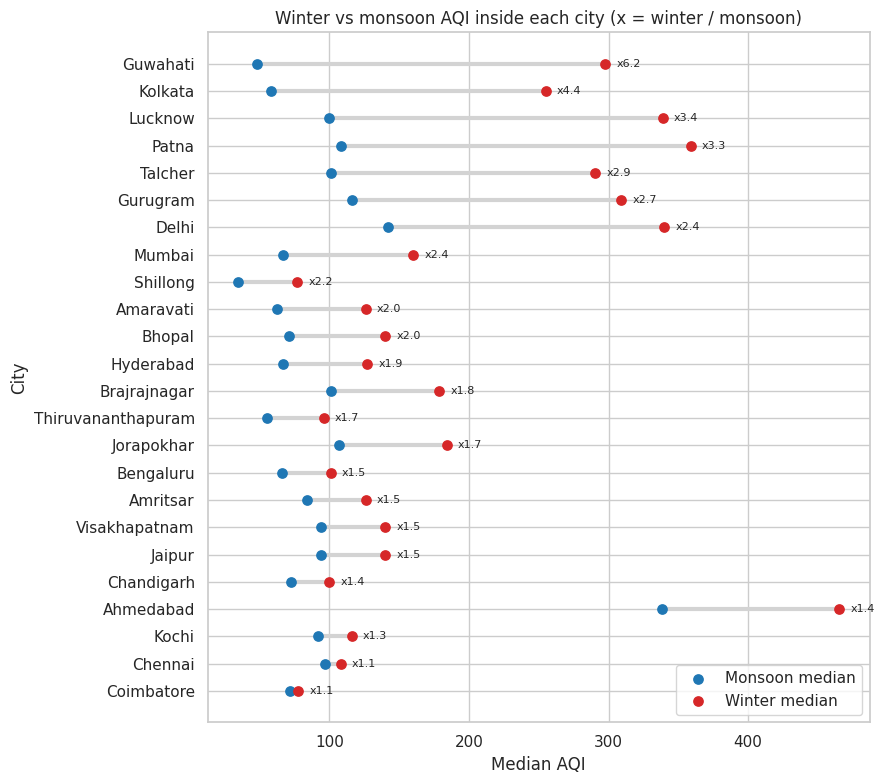

Median of the ratios by region:
Region
North-East    4.21
East          2.88
Central       1.97
North         1.95
West          1.88
South         1.51


In [10]:
q7 = df.pivot_table(index='City', columns='Season', values='AQI', aggfunc='median')
days = df.pivot_table(index='City', columns='Season', values='AQI', aggfunc='count')
q7 = q7[(days['Winter'] >= 30) & (days['Monsoon'] >= 30)].copy()      # need enough days in both seasons
q7['Ratio'] = q7['Winter'] / q7['Monsoon']
q7 = q7.sort_values('Ratio')
print('Cities compared:', len(q7), '| left out (fewer than 30 days in Winter or Monsoon):', sorted(set(df['City']) - set(q7.index)))

y = np.arange(len(q7))
fig, ax = plt.subplots(figsize=(9, 8))
ax.hlines(y, q7['Monsoon'], q7['Winter'], color='lightgrey', lw=3, zorder=1)
ax.scatter(q7['Monsoon'], y, color='tab:blue', s=45, label='Monsoon median', zorder=3)
ax.scatter(q7['Winter'],  y, color='tab:red',  s=45, label='Winter median',  zorder=3)
for i, (c, row) in enumerate(q7.iterrows()):
    ax.text(row['Winter'] + 8, i, f"x{row['Ratio']:.1f}", va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(q7.index)
ax.set_xlabel('Median AQI'); ax.set_ylabel('City'); ax.set_title('Winter vs monsoon AQI inside each city (x = winter / monsoon)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()
print('Median of the ratios by region:'); print(q7.join(city_region).groupby('Region')['Ratio'].median().round(2).sort_values(ascending=False).to_string())

**What the output shows:**
- Winter is worse than monsoon in **all 24 cities compared** (every ratio is above 1).
- The size varies a lot: **Guwahati 6.2x, Kolkata 4.4x, Lucknow 3.4x, Patna 3.3x**, Delhi 2.4x (median 142 to 340), but only **Coimbatore 1.1x, Chennai 1.1x and Kochi 1.3x**.
- By region, the median ratio is North-East 4.2, East 2.9, Central 2.0, North 1.9, West 1.9 and **South 1.5**.

**Answer and decision:** Winter really is worse inside every city, so the season effect is not an artefact of the city mix. But the effect is **strong in the north and east and weak in the south**. One global "season" feature would be wrong: Part 4 needs **city or region together with season**.

**Carried to Part 3:** Kruskal-Wallis test of AQI across the four seasons, and a permutation test of winter vs monsoon.

## Q8. Is air quality really improving year by year, or is it just the changing mix of cities?
**Why it matters:** The all-city yearly average falls sharply, but the number of cities reporting grows from 7 (2015) to 23 (2019), and the new ones are mostly cleaner southern cities. A "national improvement" claim could be false.

**Concept from class:** **Confounding** (L14) and **sampling bias** (L7): the group being measured changes over time. The fix is a *fair panel*: the same cities, with enough data, in every year.

**Chart – what it is and why we use it:** (1) A **line chart with three versions** of the trend (all cities, all except Ahmedabad, same cities every year). If the lines differ, the city mix matters; the gap between them is the size of the illusion. (2) A **bar chart** of the change for each panel city, because an overall trend can hide cities that moved the other way. We compare **March-December only**, because most cities have no Jan-Feb data in 2015, and including winter in later years but not in 2015 would be unfair.

Cities in the fair "same-cities" panel: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow']
Number of cities reporting each year  : {2015: 7, 2016: 9, 2017: 15, 2018: 18, 2019: 23}


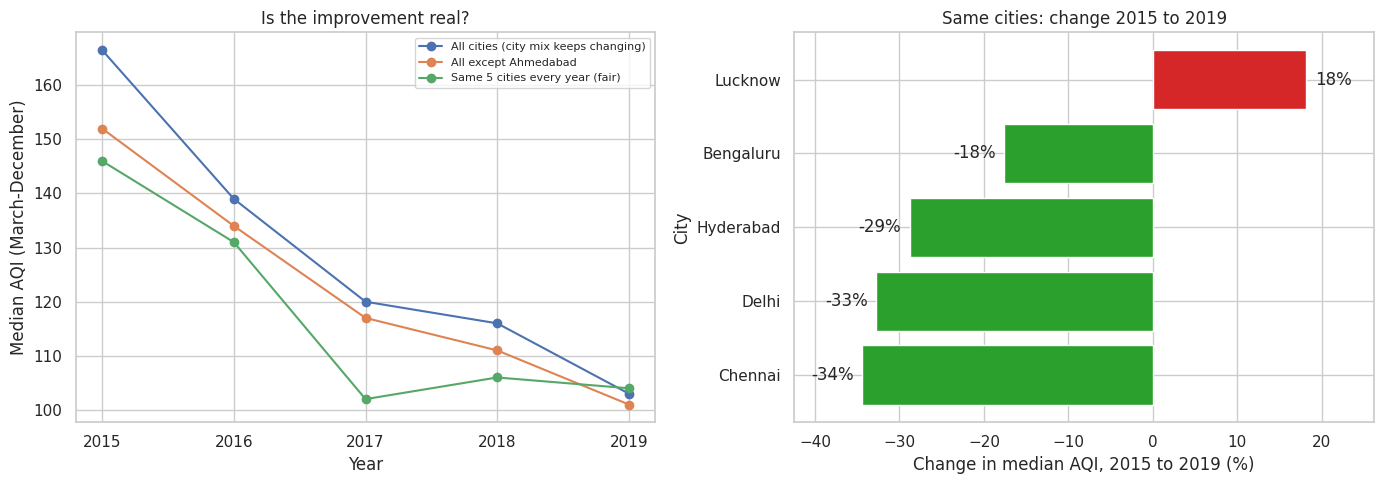

      All cities (city mix keeps changing)  All except Ahmedabad  Same 5 cities every year (fair)
Year                                                                                             
2015                                 166.0                 152.0                            146.0
2016                                 139.0                 134.0                            131.0
2017                                 120.0                 117.0                            102.0
2018                                 116.0                 111.0                            106.0
2019                                 103.0                 101.0                            104.0

Fall from 2015 to 2019 (%):
All cities (city mix keeps changing)   -38.1
All except Ahmedabad                   -33.6
Same 5 cities every year (fair)        -28.8

Median AQI of the 5 cities by year:
Year        2015   2016   2017   2018   2019
City                                        
Bengaluru  100.0   90.0

In [11]:
d = df[df['Year'].between(2015, 2019) & (df['Month'] >= 3)]            # 2020 = half year; Jan-Feb 2015 is missing for most cities -> use Mar-Dec of every year
yr_days = d.pivot_table(index='City', columns='Year', values='AQI', aggfunc='count').fillna(0)
panel = yr_days[(yr_days >= 240).all(axis=1)].index.tolist()          # cities with >= 240 of the 306 Mar-Dec days in EVERY year
print('Cities in the fair "same-cities" panel:', panel)
print('Number of cities reporting each year  :', d.groupby('Year')['City'].nunique().to_dict())

trend = pd.DataFrame({'All cities (city mix keeps changing)': d.groupby('Year')['AQI'].median(),
                      'All except Ahmedabad':                 d[d['City'] != 'Ahmedabad'].groupby('Year')['AQI'].median(),
                      'Same 5 cities every year (fair)':      d[d['City'].isin(panel)].groupby('Year')['AQI'].median()})
by_city = d[d['City'].isin(panel)].pivot_table(index='City', columns='Year', values='AQI', aggfunc='median')
chg = ((by_city[2019] / by_city[2015] - 1) * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
trend.plot(marker='o', ax=axes[0]); axes[0].set_xticks(range(2015, 2020))
axes[0].set_xlabel('Year'); axes[0].set_ylabel('Median AQI (March-December)'); axes[0].set_title('Is the improvement real?'); axes[0].legend(fontsize=8)
axes[1].barh(chg.index, chg.values, color=['tab:green' if v < 0 else 'tab:red' for v in chg.values])
for i, v in enumerate(chg.values):
    axes[1].text(v + (1 if v >= 0 else -1), i, f'{v:.0f}%', va='center', ha='left' if v >= 0 else 'right')
axes[1].set_xlabel('Change in median AQI, 2015 to 2019 (%)'); axes[1].set_ylabel('City'); axes[1].set_title('Same cities: change 2015 to 2019')
axes[1].set_xlim(min(chg.min() - 8, -10), max(chg.max(), 0) + 8)
plt.tight_layout(); plt.show()
print(trend.round(0).to_string())
print('\nFall from 2015 to 2019 (%):'); print(((trend.loc[2019] / trend.loc[2015] - 1) * 100).round(1).to_string())
print('\nMedian AQI of the 5 cities by year:'); print(by_city.round(0).to_string())

**What the output shows:**
- Number of cities reporting: 7, 9, 15, 18, 23 for 2015-2019.
- Median AQI (Mar-Dec) falls **38%** for all cities (166 to 103), **34%** without Ahmedabad (152 to 101), but only **29%** for the **same 5 cities** (146 to 104).
- The same-city panel falls from 146 to 102 by 2017 and then stays flat (106 in 2018, 104 in 2019).
- By city (2015 to 2019): **Chennai -34%, Delhi -33%, Hyderabad -29%, Bengaluru -18%, but Lucknow +18%** (it rose until 2017 and fell afterwards).

**Answer and decision:** The improvement is **real but smaller than the pooled figure**: about 9 percentage points of the "38%" come from the changing city mix. It is also **not steady** (most of the fall happened by 2017) and **not universal** (Lucknow got worse). In Part 3 and in the report we will quote the panel result, not the pooled one, and we will not use "year" as a trend feature on pooled data.

**Carried to Part 3:** permutation test on the change in city medians, 2015 vs 2019. With only 5 cities it will be weak, and we will state that as a limitation.

## Q9. Did the COVID-19 lockdown cause the 2020 drop, or was 2020 already cleaner?
**Why it matters:** Part 1 saw that Jan-Mar 2020 was already below Jan-Mar 2019, before any lockdown. If we compare only "before" and "after" in 2020, we would credit the lockdown with changes that were already under way.

**Concept from class:** **Treatment vs control** (L14). 2019 is the control: the same months, without a lockdown. For each city we compute the 2020-vs-2019 change *before* the lockdown (Jan-Mar) and *during* it (Apr-Jun). The lockdown effect is the **extra** change during the lockdown.

**Chart – what it is and why we use it:** A **paired dot plot**: for each city, a grey dot (change before the lockdown) and a red dot (change during it) joined by a line. The line length and direction are the lockdown's extra effect, so we can see whether it is consistent across cities or only an average. Cities need at least 30 days in each of the four cells; Ahmedabad is left out.

Cities compared: 18 (Ahmedabad excluded)


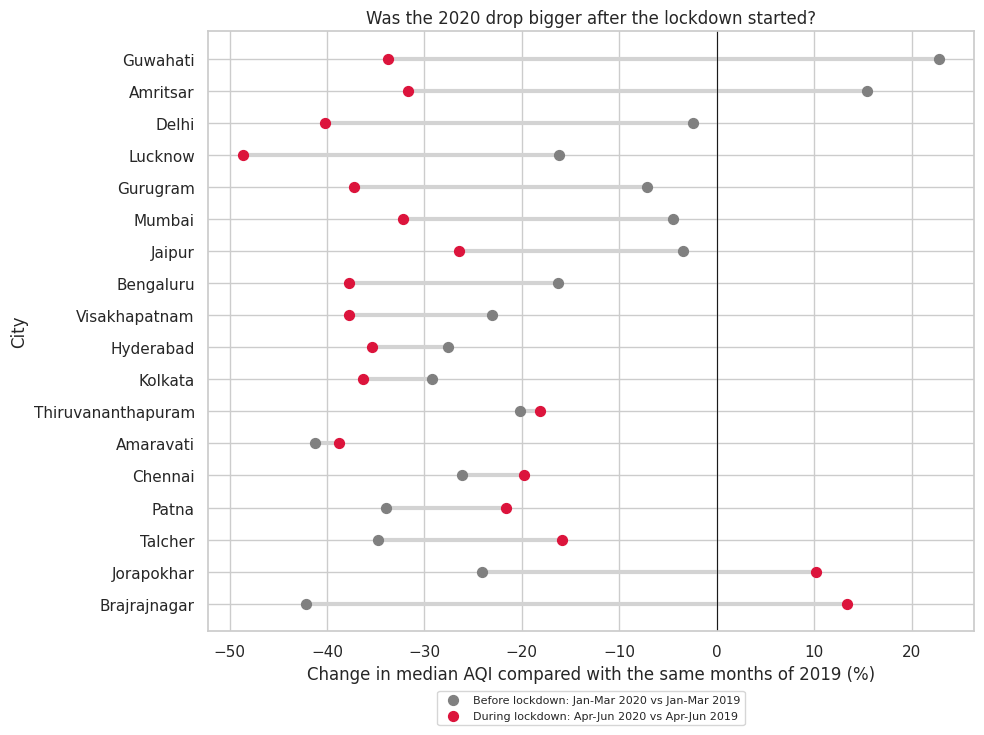

Median change vs 2019 -> before lockdown: -21.6% | during lockdown: -33.0% | extra: -11.3 points
Cities where the drop became bigger during lockdown: 11 of 18
Largest extra drops : ['Guwahati', 'Amritsar', 'Delhi', 'Lucknow', 'Gurugram']
No extra drop       : ['Brajrajnagar', 'Jorapokhar', 'Talcher', 'Patna', 'Chennai', 'Amaravati', 'Thiruvananthapuram']


In [12]:
h = ex[(ex['Month'] <= 6) & ex['Year'].isin([2019, 2020])].copy()
h['Period'] = np.where(h['Month'] <= 3, 'Before lockdown (Jan-Mar)', 'Lockdown (Apr-Jun)')
cnt = h.pivot_table(index='City', columns=['Period', 'Year'], values='AQI', aggfunc='count').fillna(0)
keep = cnt[(cnt >= 30).all(axis=1)].index                               # city needs >= 30 days in all four cells
t = h[h['City'].isin(keep)].pivot_table(index='City', columns=['Period', 'Year'], values='AQI', aggfunc='median')

q9 = pd.DataFrame({'Before lockdown': (t['Before lockdown (Jan-Mar)'][2020] / t['Before lockdown (Jan-Mar)'][2019] - 1) * 100,
                   'Lockdown':        (t['Lockdown (Apr-Jun)'][2020]        / t['Lockdown (Apr-Jun)'][2019]        - 1) * 100})
q9['Extra drop'] = q9['Lockdown'] - q9['Before lockdown']
q9 = q9.sort_values('Extra drop', ascending=False)
print('Cities compared:', len(q9), '(Ahmedabad excluded)')

y = np.arange(len(q9))
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.hlines(y, q9['Before lockdown'], q9['Lockdown'], color='lightgrey', lw=3, zorder=1)
ax.scatter(q9['Before lockdown'], y, color='grey',     s=50, label='Before lockdown: Jan-Mar 2020 vs Jan-Mar 2019', zorder=3)
ax.scatter(q9['Lockdown'],        y, color='crimson',  s=50, label='During lockdown: Apr-Jun 2020 vs Apr-Jun 2019',  zorder=3)
ax.axvline(0, color='k', lw=.8)
ax.set_yticks(y); ax.set_yticklabels(q9.index)
ax.set_xlabel('Change in median AQI compared with the same months of 2019 (%)'); ax.set_ylabel('City')
ax.set_title('Was the 2020 drop bigger after the lockdown started?')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=1, fontsize=8); plt.tight_layout(); plt.show()

print('Median change vs 2019 -> before lockdown: %.1f%% | during lockdown: %.1f%% | extra: %.1f points' % (
      q9['Before lockdown'].median(), q9['Lockdown'].median(), q9['Extra drop'].median()))
print('Cities where the drop became bigger during lockdown: %d of %d' % ((q9['Extra drop'] < 0).sum(), len(q9)))
print('Largest extra drops :', q9.sort_values('Extra drop').index[:5].tolist())
print('No extra drop       :', q9[q9['Extra drop'] >= 0].index.tolist())

**What the output shows:**
- 18 cities compared. The median change vs 2019 was **-21.6% before the lockdown** and **-33.0% during it**: an **extra drop of 11.3 points**.
- **11 of 18 cities** show a bigger drop during the lockdown; 7 do not.
- Largest extra drops: Guwahati, Amritsar, Delhi, Lucknow, Gurugram (large northern cities). Cities with no extra drop: Jorapokhar, Brajrajnagar, Talcher (coal and industrial belt), Amaravati, Patna, Chennai, Thiruvananthapuram.

**Answer and decision:** The lockdown **helped, but it is not the whole story**. About two thirds of the 2020 fall (about 22 of 33 points) was already there before the lockdown, and the extra effect appears in only 11 of 18 cities. It is largest in big northern cities, and absent where industry kept running (an interpretation, not tested). A "Lockdown" flag in the ML model would therefore overstate the effect.

**Limit:** this is not a randomised experiment (L14). Weather and rain in 2019 vs 2020 are not controlled.

**Carried to Part 3:** this is our **A/B test**: treatment = Apr-Jun 2020, control = Apr-Jun 2019. We use a permutation test on the city-level change, and a sign test for 11 of 18.

## Q10. Does Diwali cause a visible jump, or is it only the seasonal climb into winter?
**Why it matters:** Diwali falls in October-November, exactly when AQI climbs for seasonal reasons (Q7). To say the festival has an effect, the jump must be *beyond* the climb that was already happening.

**Concept from class:** Treatment window vs control (L14). The five Diwali dates (2015-2019) are lined up at day 0. The "normal" level is each city's average on days -10 to -4. We compare the day after Diwali (+1) with the three days *before* it (the climb already under way). Southern cities, where the pre-festival climb is small, act as a comparison group. Only cities with at least 3 festivals of data are used.

**Chart – what it is and why we use it:** (1) An **event-window line chart** (days from Diwali on the x-axis, AQI index on the y-axis): it shows the *timing* of the jump and how long it lasts. (2) A **dot plot** per city, with a grey dot for the 3 days before and a red dot for the day after: the line between them is the extra jump beyond the pre-festival climb. The index is divided by the city's own normal level so that cities with very different AQI can be shown together.

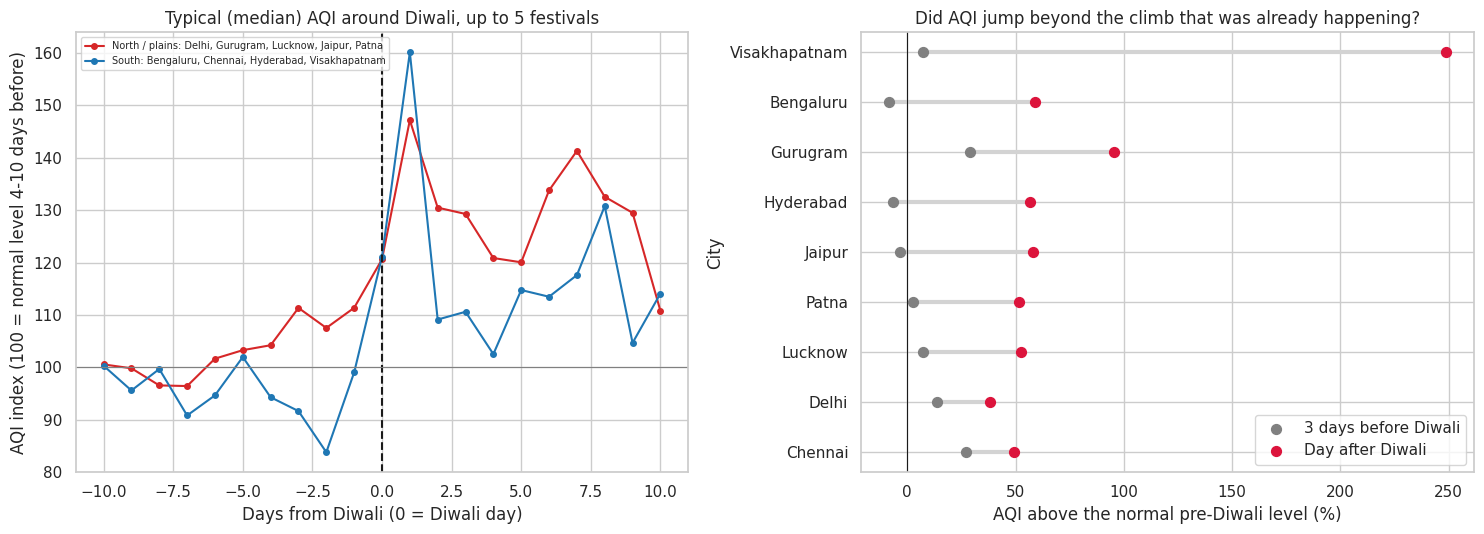

,Days -3 to -1 (already climbing),Day +1 (after Diwali),Days +4 to +7,Festivals used,Extra jump on day +1
City,,,,,
Chennai,27.0,49.0,19.0,5,22.0
Delhi,14.0,38.0,36.0,5,24.0
Lucknow,7.0,52.0,34.0,5,45.0
Patna,3.0,52.0,29.0,4,49.0
Jaipur,-3.0,58.0,1.0,3,61.0
Hyderabad,-6.0,57.0,6.0,5,63.0
Gurugram,29.0,95.0,112.0,4,66.0
Bengaluru,-8.0,59.0,18.0,5,67.0
Visakhapatnam,7.0,249.0,90.0,3,242.0


Cities where day +1 is higher than the 3 days before: 9 of 9
Median extra jump: 61 points | still above normal on days +4 to +7 (cities): 7 of 9


In [13]:
diwali = {2015: '2015-11-11', 2016: '2016-10-30', 2017: '2017-10-19', 2018: '2018-11-07', 2019: '2019-10-27'}
parts = []
for yr, day in diwali.items():
    w = df[(df['Date'] >= pd.Timestamp(day) - pd.Timedelta(days=10)) & (df['Date'] <= pd.Timestamp(day) + pd.Timedelta(days=10))].copy()
    w['Offset'] = (w['Date'] - pd.Timestamp(day)).dt.days                 # days before (-) / after (+) Diwali
    w['Diwali year'] = yr
    parts.append(w)
w = pd.concat(parts)
w = w.groupby(['City', 'Diwali year']).filter(lambda x: len(x) >= 15)     # keep city-years with at least 15 of the 21 days
w = w[w.groupby('City')['Diwali year'].transform('nunique') >= 3]         # keep cities that have at least 3 of the 5 festivals
w = w[w['City'] != 'Ahmedabad']                                           # AQI problem found in Part 1

base = w[w['Offset'].between(-10, -4)].groupby(['City', 'Diwali year'])['AQI'].mean().rename('Base')
w = w.join(base, on=['City', 'Diwali year'])
w['Index'] = w['AQI'] / w['Base'] * 100                                   # 100 = normal level of that city 4-10 days before Diwali

north, south = ['Delhi', 'Gurugram', 'Lucknow', 'Jaipur', 'Patna'], ['Bengaluru', 'Chennai', 'Hyderabad', 'Visakhapatnam']
q10 = pd.DataFrame({'Days -3 to -1 (already climbing)': w[w['Offset'].between(-3, -1)].groupby('City')['Index'].mean() - 100,
                    'Day +1 (after Diwali)':            w[w['Offset'] == 1].groupby('City')['Index'].mean() - 100,
                    'Days +4 to +7':                    w[w['Offset'].between(4, 7)].groupby('City')['Index'].mean() - 100,
                    'Festivals used':                   w.groupby('City')['Diwali year'].nunique()})
q10['Extra jump on day +1'] = q10['Day +1 (after Diwali)'] - q10['Days -3 to -1 (already climbing)']
q10 = q10.sort_values('Extra jump on day +1')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for name, cities, col in [('North / plains', north, 'tab:red'), ('South', south, 'tab:blue')]:
    m = w[w['City'].isin(cities)].groupby('Offset')['Index'].median()   # median: one extreme city cannot drag the line
    axes[0].plot(m.index, m.values, marker='o', ms=4, color=col, label=f"{name}: {', '.join(cities)}")
axes[0].axvline(0, color='k', ls='--'); axes[0].axhline(100, color='grey', lw=.8)
axes[0].set_xlabel('Days from Diwali (0 = Diwali day)'); axes[0].set_ylabel('AQI index (100 = normal level 4-10 days before)')
axes[0].set_title('Typical (median) AQI around Diwali, up to 5 festivals'); axes[0].legend(fontsize=7, loc='upper left')

y = np.arange(len(q10))
axes[1].hlines(y, q10['Days -3 to -1 (already climbing)'], q10['Day +1 (after Diwali)'], color='lightgrey', lw=3, zorder=1)
axes[1].scatter(q10['Days -3 to -1 (already climbing)'], y, color='grey',    s=50, label='3 days before Diwali', zorder=3)
axes[1].scatter(q10['Day +1 (after Diwali)'],            y, color='crimson', s=50, label='Day after Diwali',     zorder=3)
axes[1].set_yticks(y); axes[1].set_yticklabels(q10.index); axes[1].axvline(0, color='k', lw=.8)
axes[1].set_xlabel('AQI above the normal pre-Diwali level (%)'); axes[1].set_ylabel('City')
axes[1].set_title('Did AQI jump beyond the climb that was already happening?'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()
display(q10.round(0))
print('Cities where day +1 is higher than the 3 days before:', int((q10['Extra jump on day +1'] > 0).sum()), 'of', len(q10))
print('Median extra jump: %.0f points | still above normal on days +4 to +7 (cities): %d of %d' % (
      q10['Extra jump on day +1'].median(), int((q10['Days +4 to +7'] > 10).sum()), len(q10)))

**What the output shows:**
- **All 9 cities** have a higher AQI on the day after Diwali than in the 3 days before it. The median extra jump is **61 index points**.
- Day +1 is **38% above normal in Delhi, 52% in Lucknow and Patna, 57-59% in Hyderabad, Jaipur and Bengaluru, 95% in Gurugram**. Visakhapatnam shows 249%, an outlier with only 3 festivals of data.
- The pre-festival climb differs: Gurugram (+29%), Chennai (+27%) and Delhi (+14%) were already rising, whereas **Bengaluru (-8%) and Hyderabad (-6%) were below normal just before Diwali** and still jump by about 57-59%.
- **Line chart:** the southern line spikes on day +1 and drops back within a day, while the northern line climbs before Diwali and stays about 20-40% above normal for the next week.
- After the jump, **7 of 9 cities are still more than 10% above normal on days +4 to +7**; the jump fades quickly in Jaipur (+1%) and Hyderabad (+6%).

**Answer and decision:** Yes, there is a **Diwali jump beyond the seasonal climb**: it appears even in cities with no pre-climb, which supports a festival (fireworks) effect. In the north part of the high level after Diwali is the seasonal rise continuing, so the festival cannot be given all the credit. Both ideas are *associations*, not proof of cause.

**Carried to Part 3:** paired test of day +1 vs days -3 to -1 over all city-festival pairs; add a "Diwali week" feature in Part 4.

# GROUP D – How reliable is our evidence?
The last group checks the **assumptions behind everything else**: are days independent (Q11), are rankings certain (Q12), does the sampling method matter (Q13), is one number per city enough (Q14), and how predictable is tomorrow (Q15).

## Q11. Do bad-air days arrive like independent coin flips, or in streaks?
**Why it matters:** Almost every statistical test assumes that observations are independent. If one bad day makes the next bad day more likely, our 24,850 rows are worth far fewer *independent* observations, and p-values in Part 3 would look better than they should.

**Concept from class:** Each day is a **Bernoulli trial** (bad day = AQI above 200, the "Poor" limit). The number of bad days in 28 days should follow a **Binomial(n = 28, p)** distribution with mean *np* and variance *np(1-p)* if days are independent (L6). We compare this theoretical distribution with the **empirical distribution** we actually observe (L11).

**Chart – what it is and why we use it:** **Bars of the observed distribution with the Binomial curve on top.** If the days were independent, the bars would follow the red curve. Any gap shows what independence cannot explain. Delhi (bad days common) and Chennai (rare) are shown side by side. The table also gives the chance of a bad day after a bad day, compared with after a normal day.

,Months,p (bad day),Expected bad days np,Binomial variance,Observed variance,P(bad | yesterday bad),P(bad | yesterday not bad),Variance ratio
City,,,,,,,,
Delhi,63,0.651,18.223,6.363,101.262,0.915,0.158,15.914
Lucknow,56,0.494,13.830,6.999,124.561,0.891,0.106,17.797
Chennai,56,0.067,1.887,1.760,6.143,0.492,0.035,3.490
Bengaluru,57,0.021,0.601,0.588,2.212,0.375,0.014,3.762


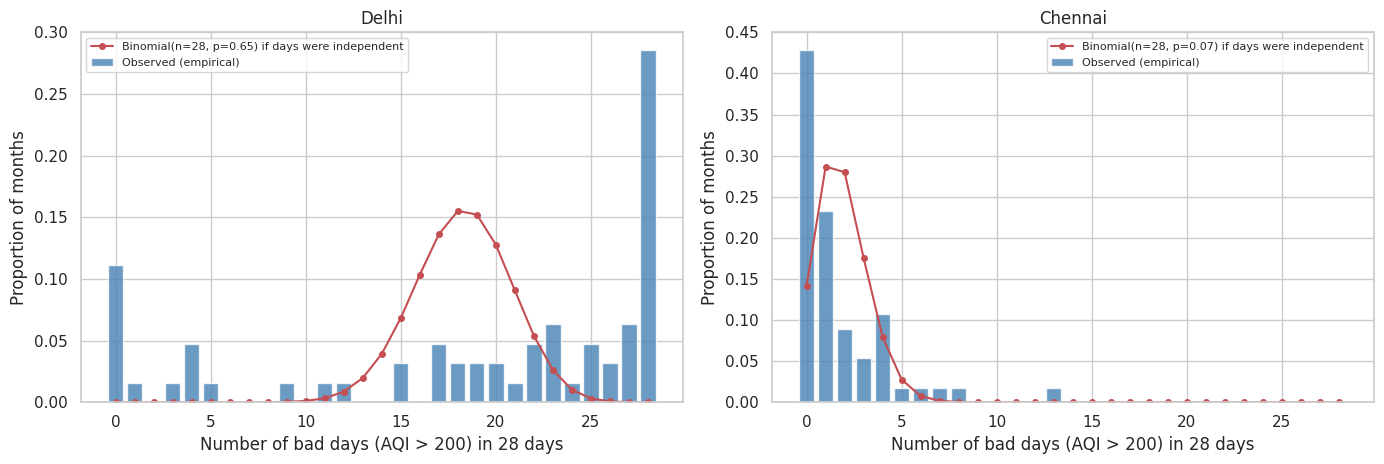

In [14]:
N, LIMIT = 28, 200            # a "month" = first 28 days of a calendar month; a bad day = AQI above 200 (Poor or worse)

def bad_days_per_month(city):
    s = df[df['City'] == city].set_index('Date')['AQI']
    bad = (s > LIMIT).astype(int)
    counts = []
    for _, b in bad.groupby([bad.index.year, bad.index.month]):
        first = b[b.index.day <= N]
        if len(first) == N: counts.append(first.sum())                   # only months with all 28 days present
    return np.array(counts)

rows, data = [], {}
for city in ['Delhi', 'Lucknow', 'Chennai', 'Bengaluru']:
    s = df[df['City'] == city].set_index('Date')['AQI'].asfreq('D')
    b = (s > LIMIT).astype(float).where(s.notna()); prev = b.shift(1)
    k = bad_days_per_month(city); p = (df.loc[df['City'] == city, 'AQI'] > LIMIT).mean()
    data[city] = (k, p)
    rows.append({'City': city, 'Months': len(k), 'p (bad day)': p, 'Expected bad days np': N * p,
                 'Binomial variance': N * p * (1 - p), 'Observed variance': k.var(ddof=1),
                 'P(bad | yesterday bad)': b[prev == 1].mean(), 'P(bad | yesterday not bad)': b[prev == 0].mean()})
q11 = pd.DataFrame(rows).set_index('City'); q11['Variance ratio'] = q11['Observed variance'] / q11['Binomial variance']
display(q11.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, city in zip(axes, ['Delhi', 'Chennai']):
    k, p = data[city]; x = np.arange(N + 1)
    ax.bar(x, np.bincount(k, minlength=N + 1) / len(k), color='steelblue', alpha=.8, label='Observed (empirical)')
    ax.plot(x, stats.binom.pmf(x, N, p), 'ro-', ms=4, label=f'Binomial(n={N}, p={p:.2f}) if days were independent')
    ax.set_xlabel(f'Number of bad days (AQI > {LIMIT}) in {N} days'); ax.set_ylabel('Proportion of months')
    ax.set_title(city); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What the output shows:**
- **Delhi:** p(bad day) = 0.65, so independent days would give about 18 bad days in 28 with variance 6.4. The observed variance is **101 (16 times larger)**. The bars pile up at **0 and 28**, with 11% of months having no bad day and about 29% having all 28 bad, while the Binomial curve expects almost none there.
- **Lucknow** 18 times larger; **Chennai and Bengaluru** about 3.5-3.8 times larger.
- **Streaks:** in Delhi, the chance of a bad day is **0.92 after a bad day** and **0.16 after a normal day** (Lucknow 0.89 vs 0.11; Chennai 0.49 vs 0.04).

**Answer and decision:** No. Bad days come in **long streaks**, so the conditions of the Binomial model (independent trials) fail. The days are strongly dependent, which has two consequences:
1. In Part 3, day-level tests overstate the evidence. We will use **monthly or yearly aggregates** or **permutation by whole blocks**, and say so.
2. In Part 4, rows are not independent, so we need a **time-ordered train/test split**, and yesterday's AQI will be a strong feature (Q15).

## Q12. Can we trust the ranking of cities by the share of Poor-or-worse days?
**Why it matters:** The cities have between 111 and 2,000 days of data. A city with 111 days can easily rank higher or lower than it "should" just by chance. A ranking without uncertainty is not a safe basis for a conclusion.

**Concept from class:** The share of bad days is a **statistic** calculated from a sample; a different sample would give a different value (L11). We simulate this with the **bootstrap**: re-sample each city's days *with replacement* 2,000 times, recompute the share each time, and take the middle 95% as an interval (empirical distribution of the statistic).

**Chart – what it is and why we use it:** An **interval (forest) plot**: one dot per city (observed share) with a line for the 95% interval, and the number of days in the label. Where two intervals overlap, we cannot say that one city is really worse than the other. A bar chart of the shares would hide all uncertainty.

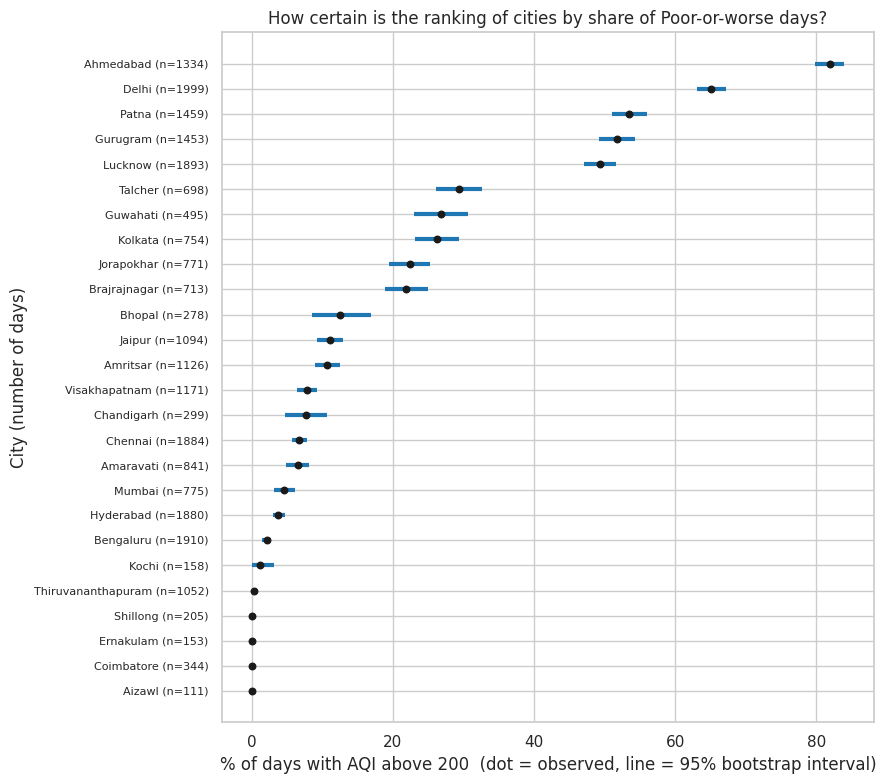

,Days,p (%),Low (%),High (%),Interval width (points)
City,,,,,
Ahmedabad,1334,81.9,79.8,84.0,4.2
Delhi,1999,65.1,63.0,67.2,4.2
Patna,1459,53.5,51.0,56.1,5.1
Gurugram,1453,51.8,49.2,54.3,5.1
Lucknow,1893,49.4,47.1,51.6,4.5
Talcher,698,29.4,26.1,32.7,6.6
Guwahati,495,26.9,23.0,30.7,7.7
Kolkata,754,26.3,23.2,29.4,6.2


,Days,Interval width (points)
City,,
Bhopal,278,8.273
Guwahati,495,7.677
Talcher,698,6.590
Kolkata,754,6.233


In [15]:
B = 2000                                       # number of bootstrap repeats
rows = []
for city, g in df.groupby('City'):
    bad = (g['AQI'] > 200).values.astype(int)  # 1 = Poor or worse day
    means = rng.choice(bad, size=(B, len(bad))).mean(axis=1)           # B re-samples of the same size, with replacement
    rows.append((city, len(bad), bad.mean(), *np.percentile(means, [2.5, 97.5])))
q12 = pd.DataFrame(rows, columns=['City', 'Days', 'p', 'Low', 'High']).set_index('City').sort_values('p')

fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(q12))
ax.hlines(y, q12['Low'] * 100, q12['High'] * 100, color='tab:blue', lw=3)
ax.scatter(q12['p'] * 100, y, color='k', zorder=3, s=22)
ax.set_yticks(y); ax.set_yticklabels([f'{c} (n={n})' for c, n in zip(q12.index, q12['Days'])], fontsize=8)
ax.set_xlabel('% of days with AQI above 200  (dot = observed, line = 95% bootstrap interval)'); ax.set_ylabel('City (number of days)')
ax.set_title('How certain is the ranking of cities by share of Poor-or-worse days?')
plt.tight_layout(); plt.show()
q12['Interval width (points)'] = (q12['High'] - q12['Low']) * 100
display(q12.sort_values('p', ascending=False).assign(p=lambda x: x['p'] * 100, Low=lambda x: x['Low'] * 100, High=lambda x: x['High'] * 100).round(1).head(8).rename(columns={'p': 'p (%)', 'Low': 'Low (%)', 'High': 'High (%)'}))
display(q12.sort_values('Interval width (points)', ascending=False).round(3).head(4)[['Days', 'Interval width (points)']])

**What the output shows:**
- **Clear at the top:** Ahmedabad 81.9% (79.8-84.0) and Delhi 65.1% (63.0-67.2). Their intervals do not touch anything else.
- **A tie in the middle:** Patna 53.5% (51.0-56.1), Gurugram 51.8% (49.2-54.3) and Lucknow 49.4% (47.1-51.6) overlap. So do Talcher, Guwahati and Kolkata (26-29%).
- **Widest intervals** belong to cities with fewer days: Bhopal (278 days, 8.3 points wide), Guwahati (7.7), Talcher (6.6) and Kolkata (6.2).
- **Zero-width intervals** for Aizawl, Shillong, Ernakulam and Coimbatore mean that **no** bad day was *seen*, not that it can never happen. The bootstrap cannot invent events that are not in the sample (a rule of thumb is about 3 / n, i.e. around 2-3% for a city with 111 days).

**Answer and decision:** Only the **top two cities and the bottom group are certain**. Patna, Gurugram and Lucknow should be presented as a **tier** with a similar risk, not as ranks 3, 4 and 5. **Caution:** Q11 showed that days come in streaks, so the real uncertainty is **larger** than these intervals.

**Carried to Part 3:** two-proportion test for Patna vs Gurugram (expected to be not significant).

## Q13. How much does the *way we sample* change the answer?
**Why it matters:** Part 1 showed that the data is unbalanced and that a few cities have much longer records. In Part 4 we will split the data into training and test sets. If the sampling method is biased, every later result is biased too, and a larger sample will not fix it.

**Concept from class:** Sampling schemes (L7, L11): **simple random**, **stratified** (by city), **systematic** (every k-th row from a random start) and **convenience** (the easiest data, here the cities with records since 2015). We treat the 24,850 rows as the population and draw 1,000 repeated samples of 300 rows with each scheme. The distribution of the sample means is the **sampling distribution** of the statistic.

**Chart – what it is and why we use it:** (1) **Overlaid density curves of the 1,000 sample means** with a line at the true mean: the distance from the line is the *bias* and the width of the curve is the *variability*. (2) A **line chart of the standard error against sample size** (simple random samples), compared with the theory SD / √n, to show how sample size affects the result.

Population: 24850 rows, true mean AQI = 166.5 | convenience pool = 12359 rows from 7 cities


,Average of sample means,Bias (avg - true),SD of sample means
Simple random,166.6,0.1,8.2
Stratified (by city),166.7,0.2,6.4
Systematic (every k-th row),166.6,0.2,4.6
Convenience (long-record cities only),201.5,35.1,9.9


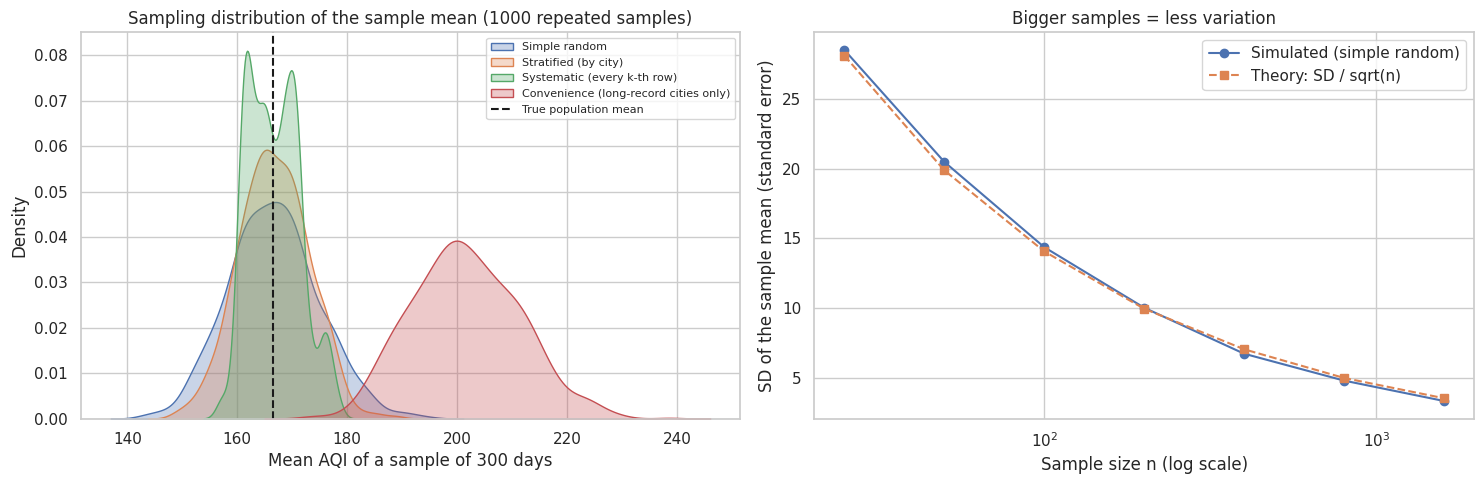

In [16]:
pop_mean, pop_sd = df['AQI'].mean(), df['AQI'].std()
n, reps = 300, 1000
early = df.groupby('City')['Year'].min().loc[lambda s: s == 2015].index          # cities that have records since 2015
easy = df[df['City'].isin(early)]['AQI']                                          # the data that is "easiest" to get
print('Population: %d rows, true mean AQI = %.1f | convenience pool = %d rows from %d cities' % (len(df), pop_mean, len(easy), len(early)))

k_step = len(df) // n
means = {
  'Simple random':             [df['AQI'].sample(n, random_state=rng).mean() for _ in range(reps)],
  'Stratified (by city)':      [df.groupby('City')['AQI'].sample(frac=n / len(df), random_state=rng).mean() for _ in range(reps)],
  'Systematic (every k-th row)': [df['AQI'].iloc[rng.integers(k_step)::k_step].mean() for _ in range(reps)],
  'Convenience (long-record cities only)': [easy.sample(n, random_state=rng).mean() for _ in range(reps)]}
summary = pd.DataFrame({k: {'Average of sample means': np.mean(v), 'Bias (avg - true)': np.mean(v) - pop_mean, 'SD of sample means': np.std(v)} for k, v in means.items()}).T
display(summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for k, v in means.items():
    sns.kdeplot(v, ax=axes[0], fill=True, alpha=.3, label=k)
axes[0].axvline(pop_mean, color='k', ls='--', label='True population mean')
axes[0].set_xlabel(f'Mean AQI of a sample of {n} days'); axes[0].set_ylabel('Density')
axes[0].set_title('Sampling distribution of the sample mean (1000 repeated samples)'); axes[0].legend(fontsize=8)

sizes = [25, 50, 100, 200, 400, 800, 1600]
sd_obs = [np.std([df['AQI'].sample(s, random_state=rng).mean() for _ in range(400)]) for s in sizes]
axes[1].plot(sizes, sd_obs, 'o-', label='Simulated (simple random)')
axes[1].plot(sizes, pop_sd / np.sqrt(sizes), 's--', label='Theory: SD / sqrt(n)')
axes[1].set_xscale('log'); axes[1].set_xlabel('Sample size n (log scale)'); axes[1].set_ylabel('SD of the sample mean (standard error)')
axes[1].set_title('Bigger samples = less variation'); axes[1].legend()
plt.tight_layout(); plt.show()

**What the output shows:**
- True mean AQI = **166.5**.
- **Simple random:** average of sample means 166.6, SD 8.2. **Stratified by city:** 166.7, SD **6.4**. **Systematic:** 166.6, SD **4.6** (the file is sorted by city, so every k-th row automatically touches every city, like stratification). All three are **unbiased**.
- **Convenience** (only the 7 long-record cities): average 201.5, a **bias of +35 AQI points**, and no reduction in bias however many rows we take.
- **Sample size:** the standard error falls from about 28 (n = 25) to about 3.4 (n = 1,600), following SD / √n almost exactly.

**Answer and decision:** A larger sample reduces *random* error but cannot repair a *biased* sampling method. Probability sampling is safe, and stratifying by city makes the estimate more precise. In Part 4 we will **split by city-stratified, time-ordered samples** and never train on "the cities that are easiest to get".

## Q14. Does one number per city hide local hot-spots?
**Why it matters:** `city_day.csv` gives one AQI per city per day. Delhi has 37 stations, so a single figure may hide neighbourhoods with very different air, which matters for health advice and for the dashboard.

**Concept from class:** **Dispersion** (range, spread) (L10) and **data integration** (L8): we join the station file with the station list. To compare stations fairly we use L14's idea of comparing under the same conditions: each station is compared with the Delhi average **of the same day**, because stations started reporting in different years and a raw station average would mix time with place. Only days with at least 10 stations reporting are used.

**Chart – what it is and why we use it:** (1) A **bar chart of each station's average deviation** from the same-day Delhi average: bars to the right are hot-spots and bars to the left are cleaner places, sorted so that the extremes are obvious. (2) A **histogram of the daily range** (highest minus lowest station on the same day), which shows how big the disagreement is on a typical day, not just on average.

Days with >= 10 stations: 976 | correlation of city_day AQI with the average of stations: 1.000
Same-day gap between highest and lowest station -> median 198, 90th percentile 312 AQI points


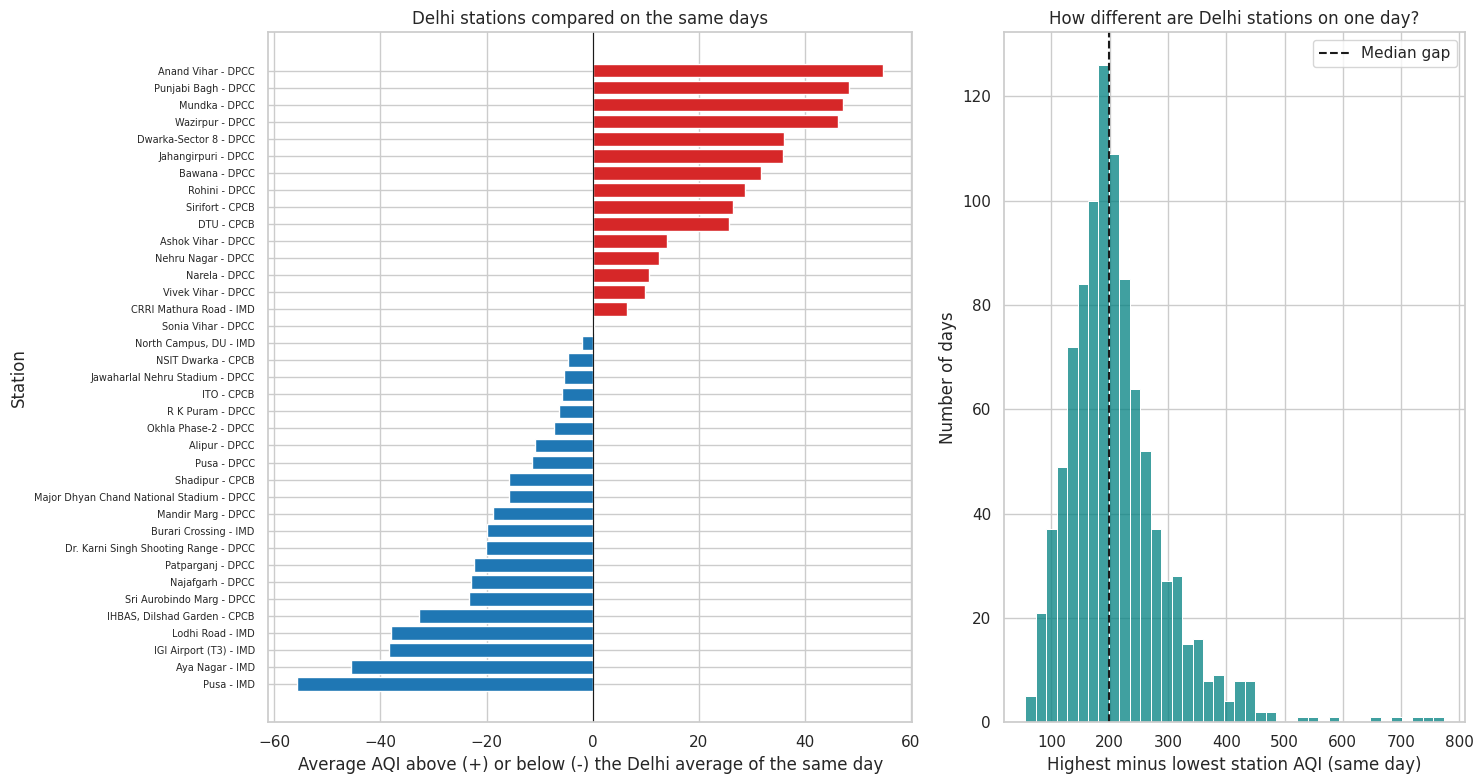

Highest: {'Punjabi Bagh - DPCC': 48.0, 'Anand Vihar - DPCC': 55.0}
Lowest : {'Pusa - IMD': -56.0, 'Aya Nagar - IMD': -46.0}

Average deviation by operating agency:
          avg deviation  stations
Operator                         
CPCB               -1.0         6
DPCC                9.0        24
IMD               -28.0         7


In [17]:
d14 = sd[sd['City'] == 'Delhi'].copy()
d14['Station'] = d14['StationName'].str.replace(', Delhi', '', regex=False)
daily = d14.groupby('Date')['AQI'].agg(Stations='count', Mean='mean', Lowest='min', Highest='max')
daily = daily[daily['Stations'] >= 10].copy()                      # only days when at least 10 stations reported
daily['Range'] = daily['Highest'] - daily['Lowest']

d14 = d14.merge(daily[['Mean']].rename(columns={'Mean': 'Delhi_mean'}), left_on='Date', right_index=True)
d14['Deviation'] = d14['AQI'] - d14['Delhi_mean']                   # station minus Delhi average of the SAME day
dev = d14.groupby('Station')['Deviation'].agg(['mean', 'count'])
dev = dev[dev['count'] >= 100].sort_values('mean')

city_aqi = df[df['City'] == 'Delhi'].set_index('Date')['AQI']
print('Days with >= 10 stations: %d | correlation of city_day AQI with the average of stations: %.3f' % (
      len(daily), daily['Mean'].corr(city_aqi.reindex(daily.index))))
print('Same-day gap between highest and lowest station -> median %.0f, 90th percentile %.0f AQI points' % (
      daily['Range'].median(), daily['Range'].quantile(.9)))

fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={'width_ratios': [1.4, 1]})
axes[0].barh(dev.index, dev['mean'], color=['tab:red' if v > 0 else 'tab:blue' for v in dev['mean']])
axes[0].axvline(0, color='k', lw=.8); axes[0].tick_params(axis='y', labelsize=7)
axes[0].set_xlabel('Average AQI above (+) or below (-) the Delhi average of the same day'); axes[0].set_ylabel('Station')
axes[0].set_title('Delhi stations compared on the same days')
sns.histplot(daily['Range'], bins=40, color='teal', ax=axes[1])
axes[1].axvline(daily['Range'].median(), color='k', ls='--', label='Median gap')
axes[1].set_xlabel('Highest minus lowest station AQI (same day)'); axes[1].set_ylabel('Number of days')
axes[1].set_title('How different are Delhi stations on one day?'); axes[1].legend()
plt.tight_layout(); plt.show()
print('Highest:', dev['mean'].tail(2).round(0).to_dict()); print('Lowest :', dev['mean'].head(2).round(0).to_dict())
dev['Operator'] = dev.index.str.split(' - ').str[-1]
print('\nAverage deviation by operating agency:'); print(dev.groupby('Operator')['mean'].agg(['mean', 'count']).round(0).rename(columns={'mean': 'avg deviation', 'count': 'stations'}).to_string())

**What the output shows:**
- The city file's Delhi AQI equals the **average of the stations** (correlation 1.000), so it is a mean of 37 different places.
- On the same day, the highest station is a **median of 198 AQI points** above the lowest (90th percentile: 312).
- **Hot-spots:** Anand Vihar (+55), Punjabi Bagh (+48), Mundka and Wazirpur (about +46 to +47). **Cleaner:** Pusa-IMD (-56) and Aya Nagar-IMD (-46).
- **By operating agency:** the 7 IMD stations average **-28**, the 6 CPCB stations -1 and the 24 DPCC stations +9.

**Answer and decision:** Yes, the city number **hides large local differences**: a typical day has a gap of about 200 AQI points between the worst and the cleanest station. The IMD stations all read lower, so part of the gap may be a difference of **equipment or agency** and not only geography. This data cannot separate the two. We use `city_day` for comparing cities, and the dashboard will include a **station-level view** for hot-spots.

## Q15. How much of today's AQI is already known from yesterday?
**Why it matters:** This decides how the ML problem should be framed. If tomorrow looks almost exactly like today, a simple "tomorrow = today" rule is a very strong baseline, and any model must beat it to be worth using.

**Concept from class:** **Covariance and correlation** (L10) between a variable and a *shifted copy of itself* (lag 1). Squaring the correlation (r²) gives the share of variation explained.

**Chart – what it is and why we use it:** (1) A **lag scatter** (yesterday on the x-axis, today on the y-axis) for Delhi, with the diagonal "no change" line: points on the line mean "same as yesterday", and the spread around it is what yesterday cannot predict. (2) A **bar chart of the lag-1 correlation for all cities**, to check that Delhi is not a special case. The calendar is filled first so that "yesterday" is always the real previous day.

Delhi: correlation between AQI today and AQI k days later: {1: np.float64(0.9), 2: np.float64(0.81), 3: np.float64(0.76), 7: np.float64(0.68), 14: np.float64(0.63), 30: np.float64(0.47)}


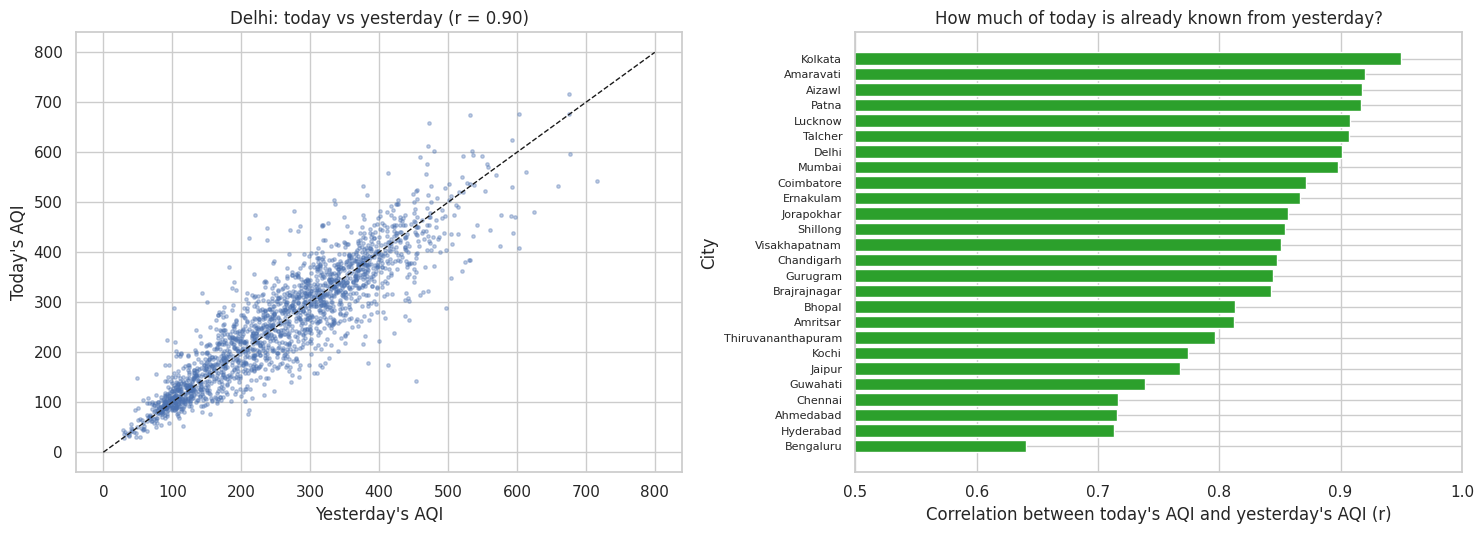

Lowest r: Bengaluru 0.64 | highest r: Kolkata 0.95 | median r 0.85 | median r^2 0.72


In [18]:
rows = []
for city, g in df.groupby('City'):
    s = g.set_index('Date')['AQI'].asfreq('D')                       # full calendar so that "yesterday" is really yesterday
    pairs = s.notna() & s.shift(1).notna()
    rows.append((city, pairs.sum(), s.corr(s.shift(1))))
q15 = pd.DataFrame(rows, columns=['City', 'Day pairs', 'r']).set_index('City').sort_values('r')

delhi = df[df['City'] == 'Delhi'].set_index('Date')['AQI'].asfreq('D')
lags = [1, 2, 3, 7, 14, 30]
print('Delhi: correlation between AQI today and AQI k days later:', {k: round(delhi.corr(delhi.shift(-k)), 2) for k in lags})

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(delhi.shift(1), delhi, s=6, alpha=.35)
axes[0].plot([0, 800], [0, 800], 'k--', lw=1)
axes[0].set_xlabel("Yesterday's AQI"); axes[0].set_ylabel("Today's AQI"); axes[0].set_title("Delhi: today vs yesterday (r = %.2f)" % q15.loc['Delhi', 'r'])
axes[1].barh(q15.index, q15['r'], color='tab:green'); axes[1].set_xlim(.5, 1)
axes[1].set_xlabel("Correlation between today's AQI and yesterday's AQI (r)"); axes[1].set_ylabel('City')
axes[1].set_title('How much of today is already known from yesterday?'); axes[1].tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
print('Lowest r: %s %.2f | highest r: %s %.2f | median r %.2f | median r^2 %.2f' % (
      q15.index[0], q15['r'].iloc[0], q15.index[-1], q15['r'].iloc[-1], q15['r'].median(), (q15['r'] ** 2).median()))

**What the output shows:**
- **Delhi:** r = **0.90** at lag 1, then 0.81 (2 days), 0.76 (3), 0.68 (7), 0.63 (14) and 0.47 (30 days). The memory fades slowly.
- **All cities:** lag-1 r runs from **0.64 (Bengaluru) to 0.95 (Kolkata)**, with a median of 0.85. The median r² is **0.72**, so yesterday explains about 72% of the variation in today's AQI (81% in Delhi).

**Answer and decision:** **Most of today's AQI is already known from yesterday.** For Part 4 this means:
1. Frame the task as **predicting next-day AQI** and use **"tomorrow = today" as the baseline** to beat.
2. Add **lag features** and a **time-ordered split** (a random split would leak).
3. This is the same dependence we saw in Q11 (streaks) and is another reason for care with p-values in Part 3.

# SUMMARY – Decisions from Part 2 and what they feed into

| # | Answer in one line | Decision / use later |
|---|---|---|
| 1 | The mean overstates a typical day in most cities (pooled mean 166 vs median 118). Delhi is the exception. | Compare cities with the **median**. |
| 2 | Two kinds of problem: chronic (Delhi, Patna, Gurugram, Lucknow) and episodic (Guwahati, Kolkata, Amritsar). | Describe cities by **level and CV**. |
| 3 | Hyderabad, Amritsar, Guwahati and Chennai have rare extreme days (kurtosis 6-24); northern cities do not. | Use **MAE and log AQI** in Part 4. |
| 4 | AQI = worst pollutant: PM2.5 in winter, PM10 in summer and monsoon; Ahmedabad is CO-driven (83%). | Ahmedabad stays separate; **frame ML carefully**. |
| 5 | Fine-particle share rises in winter and on the worst days (0.57 above AQI 300, 0.41 in monsoon). | PM2.5 is key; add **ratio** as a feature. |
| 6 | PM2.5-PM10 (0.87), NO-NOx (0.71) and Toluene-Benzene (0.73) overlap. | **Select features**; drop NOx. |
| 7 | Winter is worse than monsoon in all 24 cities, from 6.2x (Guwahati) to 1.1x (Coimbatore). | Use **city/region x season**. |
| 8 | Improvement is real but smaller (-29% vs -38% pooled), flat after 2017, and Lucknow got worse. | Quote the **fair panel**, not the pooled trend. |
| 9 | 2020 was already 22% cleaner; the lockdown added about 11 points more, in 11 of 18 cities. | **A/B test** in Part 3; not the only cause. |
| 10 | All 9 cities jump on the day after Diwali; 7 of 9 stay elevated a week later. | Paired test; **Diwali feature**. |
| 11 | Bad days come in streaks (Delhi: 0.92 after a bad day vs 0.16 otherwise). | **Block / aggregate tests**; time-ordered split. |
| 12 | Only the top two cities and the bottom group are certain; Patna, Gurugram and Lucknow tie. | Report **tiers with intervals**. |
| 13 | Random, stratified and systematic samples are unbiased; the convenience sample is +35 points off. | **Stratified, time-ordered split**. |
| 14 | Delhi's stations differ by about 200 AQI points on the same day; IMD stations read lower. | Dashboard **station view**. |
| 15 | Yesterday explains about 72% of today (median city). | **Baseline = persistence**; add lag features. |

## Hypotheses that go to Part 3 (L12, L13)
| From | Hypothesis (H0) | Test |
|---|---|---|
| Q1 | Delhi's typical AQI is not above 200 | One-sample test |
| Q4 | Season and dominant pollutant are independent | Chi-square test of independence |
| Q5 | The PM2.5/PM10 ratio is the same in winter and monsoon | Two-sample test / permutation |
| Q7 | AQI is the same in all four seasons | Kruskal-Wallis / permutation |
| Q8 | The 2019 median AQI equals the 2015 median in the same cities | Permutation test (small n) |
| Q9 | Apr-Jun 2020 vs Apr-Jun 2019 change equals the Jan-Mar change (**A/B test**) | Permutation test, sign test |
| Q10 | The day after Diwali is no higher than the 3 days before | Paired test |
| Q12 | Patna and Gurugram have the same share of bad days | Two-proportion test |

## Limits to remember
- The data is **observational**, so we found associations, not proven causes.
- Days are **dependent** (Q11), so day-level p-values will be too optimistic; we will use aggregates or block methods.
- Coverage is **unbalanced**, 2020 is half a year, and some cities have very few days.
- **Ahmedabad's CO** and the **filled values** (Part 1) remain data-quality limits.
- Q4 rebuilds AQI from daily averages; the official CPCB method uses 8-hour values for CO and O3.